In [1]:
!pip install transformers torch scikit-learn pandas numpy matplotlib seaborn tqdm wordcloud py3langid -q
!wget -q --show-progress https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.en.300.vec.gz
!gunzip -f cc.en.300.vec.gz
!wget -q --show-progress https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.id.300.vec.gz
!gunzip -f cc.id.300.vec.gz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 746.1/746.1 kB 12.3 MB/s eta 0:00:00
cc.en.300.vec.gz    100%[===================>]   1.23G   190MB/s    in 6.4s    
cc.id.300.vec.gz    100%[===================>]   1.14G   229MB/s    in 5.3s    


In [2]:
import re, time, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, precision_score, recall_score
)
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter
from tqdm.auto import tqdm
from wordcloud import WordCloud, STOPWORDS
import py3langid as langid
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
LABEL_NAMES = {0:'Negatif', 1:'Netral', 2:'Positif', 3:'Sarkasme'}
CLASS_NAMES  = ['Negatif','Netral','Positif','Sarkasme']
COLORS       = {'Negatif':'#e74c3c','Netral':'#95a5a6','Positif':'#2ecc71','Sarkasme':'#9b59b6'}
MC           = {'RNN':'#e74c3c','GRU':'#f39c12','LSTM':'#3498db','LSTM+Attention':'#2ecc71'}

print(f'Device  : {DEVICE}')
print(f'PyTorch : {torch.__version__}')

Device  : cuda
PyTorch : 2.10.0+cu128


In [3]:
CSV_PATH = '/kaggle/input/datasets/faisalakbar2442/xxxxxx/data_youtube_raw (4).csv'
df_raw   = pd.read_csv(CSV_PATH)
print(f'Data dimuat: {len(df_raw):,} baris')
print(f'Kolom      : {list(df_raw.columns)}')

def preprocess(text):
    text = str(text)
    text = re.sub(r'&#\d+;',    ' ',  text)
    text = re.sub(r'&[a-z]+;',  ' ',  text)
    text = re.sub(r'<br\s*/?>',  ' ',  text)
    text = re.sub(r'<[^>]+>',   '',   text)
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'@\w+|#\w+', '',   text)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    text = re.sub(r'([!?.])\1+', r'\1',  text)
    text = re.sub(r'[\x00-\x1f\x7f-\x9f]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df = df_raw.copy()
df['text_clean'] = df['text'].apply(preprocess)
before = len(df)
df = df.drop_duplicates(subset='text_clean')
df = df[df['text_clean'].str.split().str.len() >= 3].reset_index(drop=True)
print(f'Sebelum cleaning : {before:,}')
print(f'Sesudah cleaning : {len(df):,}')

# ── Filter bahasa: hanya pertahankan komentar Inggris & Indonesia ──────────
# Dataset ini bilingual EN-ID (fans Liverpool FC), sehingga komentar berbahasa
# lain (Cina, Rusia, Prancis, dst.) berada di luar cakupan penelitian & dibuang.
# Catatan metodologis: language identifier (py3langid, Lui & Baldwin 2012)
# kerap keliru mengklasifikasikan bahasa Indonesia informal/pendek sebagai
# bahasa serumpun (Melayu 'ms', Tagalog 'tl', Jawa 'jv') karena kemiripan
# kosakata. Berdasarkan pengecekan manual pada sampel korpus ini, mayoritas
# komentar berlabel ms/tl/jv memang berbahasa Indonesia, sehingga dipetakan
# kembali ke 'id' alih-alih dibuang. Set LANG_MAP = {} untuk filter lebih
# ketat (hanya label 'id' murni dari langid yang dipertahankan).
before_lang   = len(df)
df['lang']    = df['text_clean'].apply(lambda t: langid.classify(t)[0])

LANG_MAP = {'ms': 'id', 'tl': 'id', 'jv': 'id'}
df['lang'] = df['lang'].replace(LANG_MAP)

ALLOWED_LANGS = {'en', 'id'}
print('\nDistribusi bahasa terdeteksi (10 teratas):')
print(df['lang'].value_counts().head(10).to_string())

df = df[df['lang'].isin(ALLOWED_LANGS)].reset_index(drop=True)
df = df.drop(columns='lang')

print(f'\nSebelum filter bahasa : {before_lang:,}')
print(f'Sesudah filter bahasa : {len(df):,}')
print(f'Dibuang (non EN/ID)   : {before_lang - len(df):,} ({(before_lang - len(df)) / before_lang:.1%})')
df.head(3)

Data dimuat: 10,659 baris
Kolom      : ['video_id', 'author', 'text', 'like_count', 'published_at']
Sebelum cleaning : 10,659
Sesudah cleaning : 8,740

Distribusi bahasa terdeteksi (10 teratas):
lang
en    6487
id    1015
zh      82
es      78
da      67
nl      67
fr      67
it      65
de      63
ru      60

Sebelum filter bahasa : 8,740
Sesudah filter bahasa : 7,502
Dibuang (non EN/ID)   : 1,238 (14.2%)


,video_id,author,text,like_count,published_at,text_clean
0,ZMtvG1G1sjk,@ZainiDahlan-u1p,Diaz&#39;s departure is proof of the stupidity...,0,2026-05-02T00:55:25Z,Diaz s departure is proof of the stupidity Liv...
1,ZMtvG1G1sjk,@denryhutabarat4135,kebodohan terbesar sepanjang masa Liverpool : ...,0,2026-04-29T23:15:09Z,kebodohan terbesar sepanjang masa Liverpool : ...
2,ZMtvG1G1sjk,@LegenD9555pyke,Arne kick salah play with psg arne bye,1,2026-04-09T10:23:48Z,Arne kick salah play with psg arne bye


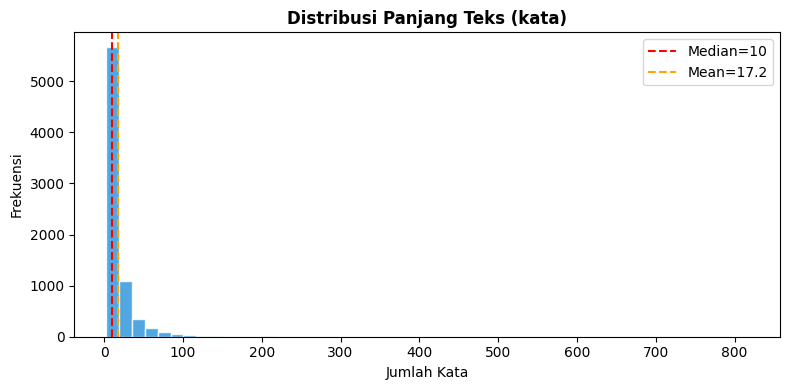

Total komentar : 7,502
Median panjang : 10 kata
Mean panjang   : 17.2 kata
Max panjang    : 817 kata


In [4]:
text_len = df['text_clean'].str.split().str.len()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(text_len, bins=50, color='#3498db', edgecolor='white', alpha=0.85)
ax.axvline(text_len.median(), color='red', linestyle='--',
           label=f'Median={text_len.median():.0f}')
ax.axvline(text_len.mean(), color='orange', linestyle='--',
           label=f'Mean={text_len.mean():.1f}')
ax.set_title('Distribusi Panjang Teks (kata)', fontweight='bold')
ax.set_xlabel('Jumlah Kata'); ax.set_ylabel('Frekuensi')
ax.legend()
plt.tight_layout()
plt.savefig('eda_panjang_teks.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Total komentar : {len(df):,}')
print(f'Median panjang : {text_len.median():.0f} kata')
print(f'Mean panjang   : {text_len.mean():.1f} kata')
print(f'Max panjang    : {text_len.max()} kata')

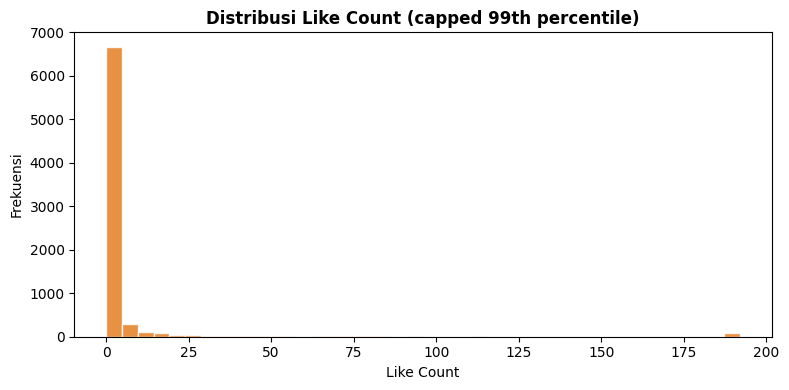

Like count — median : 0
Like count — mean   : 8.1
Like count — max    : 1909
Komentar tanpa like : 4,977


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
likes = df['like_count'].clip(upper=df['like_count'].quantile(0.99))
ax.hist(likes, bins=40, color='#e67e22', edgecolor='white', alpha=0.85)
ax.set_title('Distribusi Like Count (capped 99th percentile)', fontweight='bold')
ax.set_xlabel('Like Count'); ax.set_ylabel('Frekuensi')
plt.tight_layout()
plt.savefig('eda_like_count.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Like count — median : {df["like_count"].median():.0f}')
print(f'Like count — mean   : {df["like_count"].mean():.1f}')
print(f'Like count — max    : {df["like_count"].max()}')
print(f'Komentar tanpa like : {(df["like_count"]==0).sum():,}')

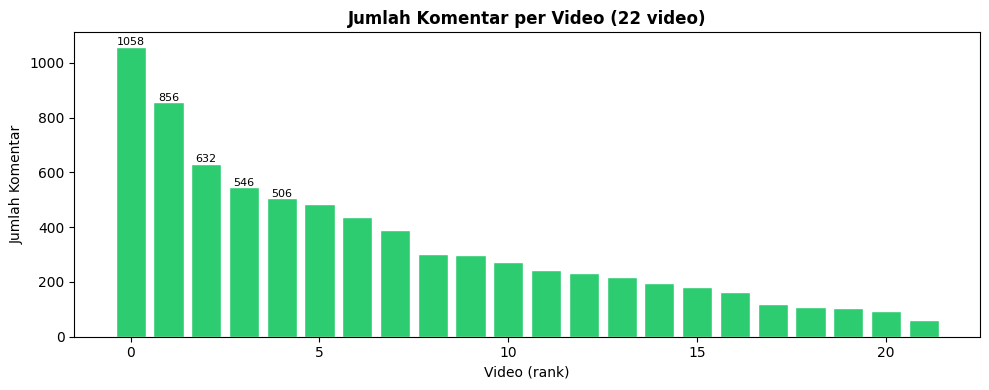

Total video     : 22
Video terbanyak : 1058 komentar
Rata-rata       : 341 komentar per video


In [6]:
vc = df['video_id'].value_counts()

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(range(len(vc)), vc.values, color='#2ecc71', edgecolor='white')
ax.set_title(f'Jumlah Komentar per Video ({len(vc)} video)', fontweight='bold')
ax.set_xlabel('Video (rank)'); ax.set_ylabel('Jumlah Komentar')
for i, (bar, v) in enumerate(zip(bars, vc.values)):
    if i < 5:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
                f'{v}', ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('eda_per_video.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Total video     : {len(vc)}')
print(f'Video terbanyak : {vc.max()} komentar')
print(f'Rata-rata       : {vc.mean():.0f} komentar per video')

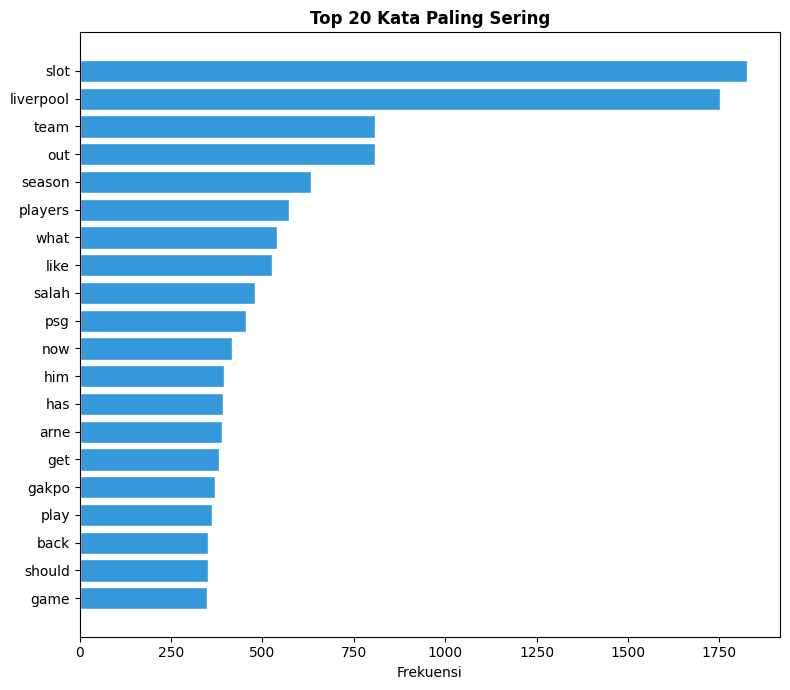

Token unik : 10,485


In [7]:
import re as _re

STOPWORDS = {
    'the','a','an','is','it','in','on','to','of','and','i','was','for',
    'at','be','this','that','with','are','have','you','we','he','she',
    'they','my','me','his','her','our','not','no','but','so','if','or',
    'as','do','did','had','can','will','just','up','by','from','all',
    'im','its','been','yang','di','dan','ini','itu','ke','ada','nya',
    's','t','don','doesn','re','ve','ll','d','m',
}

EMOJI_PAT = _re.compile(
    "[\U0001F600-\U0001F64F\U0001F300-\U0001F5FF"
    "\U0001F680-\U0001F9FF\u2600-\u26FF\u2700-\u27BF]+",
    flags=_re.UNICODE
)

def basic_clean(text):
    return _re.sub(r'[^\w\s]', ' ', str(text).lower())

all_words, all_emojis = [], []
for t in df['text_clean']:
    all_words.extend(basic_clean(t).split())
    all_emojis.extend(EMOJI_PAT.findall(str(t)))

word_freq  = Counter(w for w in all_words if w not in STOPWORDS and len(w) > 1)
emoji_freq = Counter(all_emojis)
top_words  = dict(word_freq.most_common(20))

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(list(top_words.keys())[::-1], list(top_words.values())[::-1],
        color='#3498db', edgecolor='white')
ax.set_title('Top 20 Kata Paling Sering', fontweight='bold')
ax.set_xlabel('Frekuensi')
plt.tight_layout()
plt.savefig('eda_top_kata.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Token unik : {len(word_freq):,}')

In [8]:
print('='*50)
print('STATISTIK DESKRIPTIF DATASET')
print('='*50)

tl = df['text_clean'].str.split().str.len()
print(f'Total komentar   : {len(df):,}')
print(f'Rata-rata kata   : {tl.mean():.1f}')
print(f'Median kata      : {tl.median():.0f}')
print(f'Std kata         : {tl.std():.1f}')
print(f'Min kata         : {tl.min()}')
print(f'Max kata         : {tl.max()}')
print(f'Total token unik : {len(word_freq):,}')
print(f'Komentar tanpa like: {(df["like_count"]==0).sum():,}')

STATISTIK DESKRIPTIF DATASET
Total komentar   : 7,502
Rata-rata kata   : 17.2
Median kata      : 10
Std kata         : 25.2
Min kata         : 3
Max kata         : 817
Total token unik : 10,485
Komentar tanpa like: 4,977


In [9]:
ROBERTA_MODEL = 'cardiffnlp/twitter-roberta-base-sentiment-latest'
print(f'Loading sentimen model: {ROBERTA_MODEL}')
sent_pipe = pipeline(
    'text-classification', model=ROBERTA_MODEL,
    device=0 if torch.cuda.is_available() else -1,
    truncation=True, max_length=128, batch_size=32,
)

def get_sentiment_label(result):
    raw = result['label'].lower()
    if 'positive' in raw: return 'positif'
    if 'negative' in raw: return 'negatif'
    return 'netral'

sentiments, sent_conf = [], []
texts = df['text_clean'].tolist()
for i in tqdm(range(0, len(texts), 32), desc='Labeling Sentimen'):
    batch = texts[i:i+32]
    try:
        res = sent_pipe(batch, truncation=True, max_length=128)
        for r in res:
            sentiments.append(get_sentiment_label(r))
            sent_conf.append(round(r['score'], 4))
    except:
        sentiments.extend(['netral'] * len(batch))
        sent_conf.extend([0.5] * len(batch))

df['sentimen']  = sentiments
df['sent_conf'] = sent_conf
print('Distribusi sentimen:')
print(df['sentimen'].value_counts())

Loading sentimen model: cardiffnlp/twitter-roberta-base-sentiment-latest


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/501M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.pooler.dense.weight     | UNEXPECTED |  | 
roberta.embeddings.position_ids | UNEXPECTED |  | 
roberta.pooler.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

... (2 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Labeling Sentimen:   0%|          | 0/235 [00:00<?, ?it/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Distribusi sentimen:
sentimen
negatif    3435
netral     3079
positif     988
Name: count, dtype: int64


In [10]:
ZS_MODEL = 'MoritzLaurer/mDeBERTa-v3-base-mnli-xnli'
print(f'Loading zero-shot sarcasm model: {ZS_MODEL}')
zs_pipe = pipeline(
    'zero-shot-classification', model=ZS_MODEL,
    device=0 if torch.cuda.is_available() else -1,
    truncation=True,
)

SARC_LABELS    = ['sarcasm', 'not sarcasm']
SARC_THRESHOLD = 0.75   # ← dari 0.85

SARC_POSITIVE_WORDS = [
    'great','brilliant','genius','outstanding','amazing','fantastic',
    'perfect','wonderful','excellent','superb','wow','clearly','obviously',
    'love how','love the way','well done','nice job','good job',
    'masterclass','world class','incredible','sensational','magnificent',
    'hebat','luar biasa','bagus','keren','mantap','top','sempurna',
    'terbaik','emang jago','emang hebat','emang bagus',
    'juara','brilian','jago','konsisten',
]
GENUINE_SIGNALS = [
    'love you','i love','aku suka','saya suka','ynwa',
    'sack','out','resign','fired','useless','terrible','awful',
    'worst','hate','benci','buruk','sampah','😡','😢','😭','❤️','🔥','💔',
]
SARC_EMOJIS = ['😂','🤣','😏','🙄','😒','🙃']

def is_candidate_sarcasm(text):
    tl             = text.lower()
    has_pos        = any(kw in tl for kw in SARC_POSITIVE_WORDS)
    has_sarc_emoji = any(e in text for e in SARC_EMOJIS)
    if not (has_pos or has_sarc_emoji):
        return False
    if any(kw in tl for kw in GENUINE_SIGNALS):
        return False
    if len(tl.split()) < 4:   # ← dari 5
        return False
    return True

sarc_labels, sarc_scores = [], []
texts       = df['text_clean'].tolist()
n_candidate = sum(1 for t in texts if is_candidate_sarcasm(t))
print(f'Kandidat zero-shot: {n_candidate:,} / {len(texts):,}')

for i in tqdm(range(0, len(texts), 16), desc='Zero-Shot Sarkasme'):
    batch = texts[i:i+16]
    for text in batch:
        if not is_candidate_sarcasm(text):
            sarc_labels.append(0); sarc_scores.append(0.0)
            continue
        try:
            out   = zs_pipe(text, SARC_LABELS, truncation=True, max_length=128)
            score = out['scores'][out['labels'].index('sarcasm')]
            sarc_labels.append(1 if score >= SARC_THRESHOLD else 0)
            sarc_scores.append(round(score, 4))
        except:
            sarc_labels.append(0); sarc_scores.append(0.0)

df['sarkasme']   = sarc_labels
df['sarc_score'] = sarc_scores
print(f'Terdeteksi sarkasme: {sum(sarc_labels):,}')

Loading zero-shot sarcasm model: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/558M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli
Key                             | Status     |  | 
--------------------------------+------------+--+-
deberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json: 0.00B [00:00, ?B/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Kandidat zero-shot: 1,109 / 7,502


Zero-Shot Sarkasme:   0%|          | 0/469 [00:00<?, ?it/s]

Terdeteksi sarkasme: 618


In [11]:
FOOTBALL_ASPECTS = {
    'pemain':  ['pemain','striker','midfielder','defender','bek','penyerang',
                'player','forward','winger','captain','salah','van dijk',
                'konate','gakpo','diaz','darwin','nunez','mcallister',
                'mamardashvili','frimpong','kerkez','wirtz','alonso'],
    'pelatih': ['pelatih','coach','manager','manajer','taktik','formasi',
                'tactical','formation','gaffer','arne','slot','klopp'],
    'wasit':   ['wasit','referee','ref','var','offside','penalty','card',
                'foul','handball','decision'],
    'tim':     ['tim','team','klub','club','squad','transfer','liverpool','lfc',
                'reds','kop','anfield','board','management'],
    'kiper':   ['kiper','goalkeeper','gk','keeper','mamardashvili','alisson',
                'save','clean sheet'],
}

def detect_aspect(text):
    tl = text.lower()
    for asp, kws in FOOTBALL_ASPECTS.items():
        if any(kw in tl for kw in kws):
            return asp
    return 'umum'

def make_label(row):
    if row['sarkasme'] == 1:         return 3
    if row['sentimen'] == 'negatif': return 0
    if row['sentimen'] == 'netral':  return 1
    return 2

df['aspek']         = df['text_clean'].apply(detect_aspect)
df['label']         = df.apply(make_label, axis=1)
df['absa_sentimen'] = df.apply(
    lambda r: 'sarkasme' if r['label'] == 3 else r['sentimen'], axis=1)

print('=== DISTRIBUSI LABEL ===')
for k in [0,1,2,3]:
    v = (df['label']==k).sum()
    print(f'  {LABEL_NAMES[k]:<10}: {v:>5} ({v/len(df):.1%})')

ASPECT_NAMES  = ['pemain', 'pelatih', 'wasit', 'tim', 'kiper', 'umum']
ASPECT2TOKEN  = {asp: f'<ASP_{asp.upper()}>' for asp in ASPECT_NAMES}
ASPECT_TOKENS = list(ASPECT2TOKEN.values())
print(f'Aspect tokens: {ASPECT_TOKENS}')

=== DISTRIBUSI LABEL ===
  Negatif   :  3266 (43.5%)
  Netral    :  2734 (36.4%)
  Positif   :   884 (11.8%)
  Sarkasme  :   618 (8.2%)
Aspect tokens: ['<ASP_PEMAIN>', '<ASP_PELATIH>', '<ASP_WASIT>', '<ASP_TIM>', '<ASP_KIPER>', '<ASP_UMUM>']


VALIDASI DATASET BERLABEL -- Kepercayaan Weak-Supervision

[1] Confidence RoBERTa sentiment per kelas label akhir:
  Negatif   : mean=0.788  median=0.831  <0.6=13.3%
  Netral    : mean=0.708  median=0.726  <0.6=24.8%
  Positif   : mean=0.796  median=0.850  <0.6=17.3%
  Sarkasme  : mean=0.707  median=0.728  <0.6=29.0%

[2] Label non-Sarkasme dengan sent_conf < 0.6: 1,263 dari 6,884 (18.3%) -- kandidat paling berisiko noisy

[3] Dari 618 label Sarkasme, 127 (20.6%) skornya cuma 0.75-0.80 (mepet ambang, paling gampang salah kalau threshold digeser dikit)


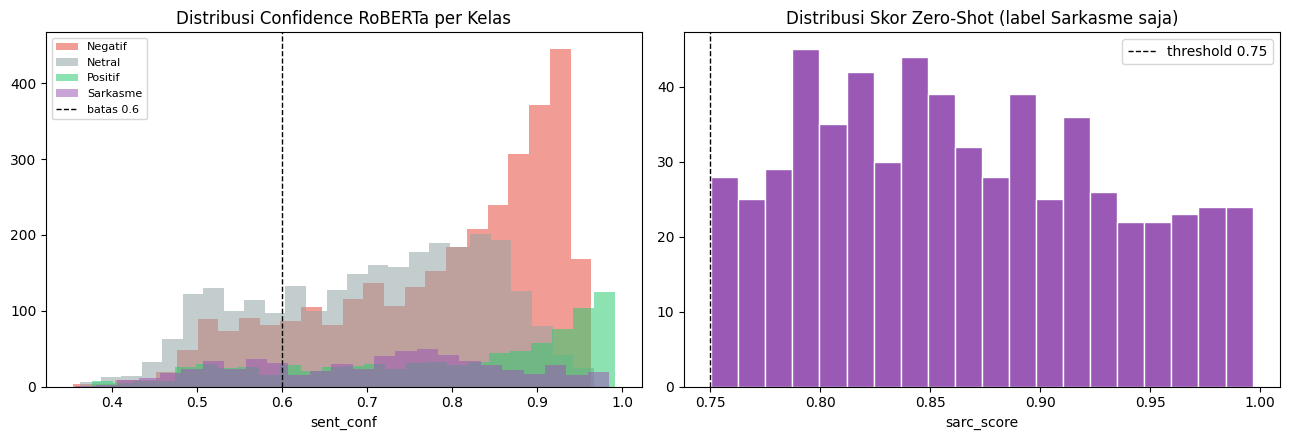

In [12]:
# ── VALIDASI DATASET BERLABEL (1/3): Kepercayaan Model Weak-Supervision ─────
print('='*65)
print('VALIDASI DATASET BERLABEL -- Kepercayaan Weak-Supervision')
print('='*65)

# [1] Confidence RoBERTa (sent_conf) per kelas label akhir
print('\n[1] Confidence RoBERTa sentiment per kelas label akhir:')
for k in [0, 1, 2, 3]:
    sub = df[df['label'] == k]['sent_conf']
    print(f'  {LABEL_NAMES[k]:<10}: mean={sub.mean():.3f}  median={sub.median():.3f}  '
          f'<0.6={100*(sub < 0.6).mean():.1f}%')

# [2] Label non-Sarkasme dengan confidence RENDAH -> paling berisiko salah label
LOW_CONF_THRESH = 0.6
low_conf = df[(df['label'] != 3) & (df['sent_conf'] < LOW_CONF_THRESH)]
n_non_sarc = (df['label'] != 3).sum()
print(f'\n[2] Label non-Sarkasme dengan sent_conf < {LOW_CONF_THRESH}: '
      f'{len(low_conf):,} dari {n_non_sarc:,} '
      f'({100*len(low_conf)/n_non_sarc:.1f}%) -- kandidat paling berisiko noisy')

# [3] Untuk Sarkasme: seberapa dekat sarc_score ke threshold (SARC_THRESHOLD)?
sarc = df[df['label'] == 3]
near_thresh = sarc[(sarc['sarc_score'] >= SARC_THRESHOLD) & (sarc['sarc_score'] < SARC_THRESHOLD + 0.05)]
print(f'\n[3] Dari {len(sarc):,} label Sarkasme, {len(near_thresh):,} '
      f'({100*len(near_thresh)/max(len(sarc),1):.1f}%) skornya cuma {SARC_THRESHOLD}-{SARC_THRESHOLD+0.05:.2f} '
      f'(mepet ambang, paling gampang salah kalau threshold digeser dikit)')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for k in [0, 1, 2, 3]:
    axes[0].hist(df[df['label']==k]['sent_conf'], bins=25, alpha=0.55,
                 label=LABEL_NAMES[k], color=COLORS[LABEL_NAMES[k]])
axes[0].axvline(LOW_CONF_THRESH, color='black', linestyle='--', linewidth=1, label=f'batas {LOW_CONF_THRESH}')
axes[0].set_title('Distribusi Confidence RoBERTa per Kelas'); axes[0].set_xlabel('sent_conf'); axes[0].legend(fontsize=8)

axes[1].hist(sarc['sarc_score'], bins=20, color=COLORS['Sarkasme'], edgecolor='white')
axes[1].axvline(SARC_THRESHOLD, color='black', linestyle='--', linewidth=1, label=f'threshold {SARC_THRESHOLD}')
axes[1].set_title('Distribusi Skor Zero-Shot (label Sarkasme saja)'); axes[1].set_xlabel('sarc_score'); axes[1].legend()

plt.tight_layout(); plt.show()


In [13]:
# ── VALIDASI DATASET BERLABEL (2/3): Cakupan Rule-Gate & Konsistensi Duplikat ──
print('='*65)
print('VALIDASI -- Cakupan Rule-Gate Sarkasme & Konsistensi Label')
print('='*65)

# [1] Funnel: berapa banyak komentar yang SEMPAT dinilai zero-shot model,
#     vs otomatis 'not sarcasm' karena gagal lolos keyword gate (is_candidate_sarcasm)
n_total     = len(df)
n_candidate = df['text_clean'].apply(is_candidate_sarcasm).sum()
n_confirmed = (df['sarkasme'] == 1).sum()
print(f'\n[1] Funnel rule-gate zero-shot sarkasme:')
print(f'  Total komentar                            : {n_total:,}')
print(f'  Lolos filter kata kunci (dinilai model)    : {n_candidate:,} ({100*n_candidate/n_total:.1f}%)')
print(f'  Dikonfirmasi sarkasme (skor >= {SARC_THRESHOLD})       : {n_confirmed:,} '
      f'({100*n_confirmed/max(n_candidate,1):.1f}% dari kandidat)')
print(f'  CATATAN: {100*(1-n_candidate/n_total):.1f}% komentar TIDAK PERNAH dinilai model zero-shot --')
print(f'  otomatis dianggap bukan sarkasme kalau nggak mengandung kata/emoji pemicu')
print(f'  di SARC_POSITIVE_WORDS/SARC_EMOJIS. Ini batasan by-design, perlu disebut')
print(f'  di bab metodologi/limitasi (recall sarkasme dibatasi cakupan keyword gate).')

# [2] Duplikat teks dengan label BERBEDA -> sinyal inkonsistensi/noise
dup_mask         = df.duplicated(subset='text_clean', keep=False)
dups              = df[dup_mask]
conflict_groups   = dups.groupby('text_clean')['label'].nunique()
n_conflict_texts  = (conflict_groups > 1).sum()
print(f'\n[2] Cek konsistensi teks duplikat:')
print(f'  Teks yang muncul >1 kali   : {dups["text_clean"].nunique():,}')
print(f'  ...dengan label BERBEDA    : {n_conflict_texts:,} teks (berpotensi noise/inkonsisten)')
if n_conflict_texts > 0:
    print(f'\n  Contoh (maks 5):')
    examples = conflict_groups[conflict_groups > 1].index[:5]
    for t in examples:
        lbls = [LABEL_NAMES[l] for l in df[df['text_clean'] == t]['label']]
        preview = t[:70] + ('...' if len(t) > 70 else '')
        print(f'   - "{preview}" -> {lbls}')


VALIDASI -- Cakupan Rule-Gate Sarkasme & Konsistensi Label

[1] Funnel rule-gate zero-shot sarkasme:
  Total komentar                            : 7,502
  Lolos filter kata kunci (dinilai model)    : 1,109 (14.8%)
  Dikonfirmasi sarkasme (skor >= 0.75)       : 618 (55.7% dari kandidat)
  CATATAN: 85.2% komentar TIDAK PERNAH dinilai model zero-shot --
  otomatis dianggap bukan sarkasme kalau nggak mengandung kata/emoji pemicu
  di SARC_POSITIVE_WORDS/SARC_EMOJIS. Ini batasan by-design, perlu disebut
  di bab metodologi/limitasi (recall sarkasme dibatasi cakupan keyword gate).

[2] Cek konsistensi teks duplikat:
  Teks yang muncul >1 kali   : 0
  ...dengan label BERBEDA    : 0 teks (berpotensi noise/inkonsisten)


In [14]:
# ── VALIDASI DATASET BERLABEL (3/3): Sampel Stratified untuk Cross-Check Manual ──
print('='*65)
print('VALIDASI -- Sampel Stratified untuk Cross-Check Manual')
print('='*65)

N_PER_CLASS = 30   # total sampel = 4 x 30 = 120 (standar laporan reliability weak-supervision)

samples = []
for k in [0, 1, 2, 3]:
    pool = df[df['label'] == k]
    n    = min(N_PER_CLASS, len(pool))
    samples.append(pool.sample(n=n, random_state=SEED))
df_validation_sample = pd.concat(samples).sample(frac=1, random_state=SEED).reset_index(drop=True)

df_validation_sample_out = df_validation_sample[['text_clean', 'label', 'sent_conf', 'sarc_score']].copy()
df_validation_sample_out['label_nama']   = df_validation_sample_out['label'].map(LABEL_NAMES)
df_validation_sample_out['label_manual'] = ''   # <- isi manual: Negatif/Netral/Positif/Sarkasme
df_validation_sample_out['setuju']       = ''   # <- isi manual: y / n

out_path = 'sampel_validasi_manual.csv'
df_validation_sample_out.to_csv(out_path, index=False)
print(f'{len(df_validation_sample_out)} sampel ({N_PER_CLASS}/kelas) disimpan ke: {out_path}')

df_validation_sample_out.head(10)


VALIDASI -- Sampel Stratified untuk Cross-Check Manual
120 sampel (30/kelas) disimpan ke: sampel_validasi_manual.csv


,text_clean,label,sent_conf,sarc_score,label_nama,label_manual,setuju
0,Kebodohan ipul adalah melepas diaz demi buang2...,1,0.8251,0.0000,Netral,,
1,Slot out now!,1,0.7456,0.0000,Netral,,
2,get rid now,0,0.6092,0.0000,Negatif,,
3,NTI second leg Liverpool come back .,1,0.7804,0.0000,Netral,,
4,i hope at Anfeld you ll no longer be a part of...,0,0.8807,0.7496,Negatif,,
5,Szoboszlai two such legendary free kick goals ...,2,0.9517,0.0000,Positif,,
6,Good gool keeper,2,0.8231,0.0000,Positif,,
7,"Slot please change something, tactics wise, I ...",0,0.8402,0.0000,Negatif,,
8,Only arsenal left. May English club be in final,1,0.5612,0.0000,Netral,,
9,150 Million striker LORD ISAK is very disgusti...,3,0.9290,0.8328,Sarkasme,,


In [15]:
# ── VALIDASI DATASET BERLABEL: Hitung Agreement (JALANKAN SETELAH CSV DIISI MANUAL) ──

from IPython.display import display

try:
    df_check = pd.read_csv(
        '/kaggle/input/datasets/faisalakbar2442/validasi-sampel/sampel_validasi_annotated_v2_kiw - sampel_validasi_annotated_v2.csv'
    )

    filled = df_check[df_check['label_manual'].astype(str).str.strip() != '']

    if len(filled) == 0:
        print("Kolom label_manual masih kosong semua -- isi dulu sampel_validasi_manual.csv sebelum menjalankan cell ini.")
    else:
        from sklearn.metrics import accuracy_score, cohen_kappa_score

        y_weak = filled['label_nama']
        y_manual = filled['label_manual'].astype(str).str.strip().str.capitalize()

        acc = accuracy_score(y_weak, y_manual)
        kappa = cohen_kappa_score(y_weak, y_manual)

        print("=" * 70)
        print("HASIL VALIDASI LABEL")
        print("=" * 70)
        print(f"Jumlah sampel tervalidasi : {len(filled)} / {len(df_check)}")
        print(f"Agreement (Accuracy)      : {acc:.2%}")
        print(f"Cohen's Kappa             : {kappa:.3f}")

        # Interpretasi Kappa
        if kappa < 0.20:
            interpretasi = "Slight"
        elif kappa < 0.40:
            interpretasi = "Fair"
        elif kappa < 0.60:
            interpretasi = "Moderate"
        elif kappa < 0.80:
            interpretasi = "Substantial"
        else:
            interpretasi = "Almost Perfect"

        print(f"Interpretasi              : {interpretasi}")
        print("=" * 70)

        # Data yang tidak sesuai
        disagree = filled[y_weak != y_manual]

        print(f"\nJumlah ketidaksepakatan : {len(disagree)} dari {len(filled)} sampel\n")

        if len(disagree) > 0:
            disagree_show = disagree[
                ['text_clean', 'label_nama', 'label_manual']
            ].reset_index(drop=True)

            # Tambahkan nomor urut
            disagree_show.index += 1
            disagree_show.index.name = "No"

            display(disagree_show)

        else:
            print("Semua sampel sesuai (100% agreement).")

except FileNotFoundError:
    print("File sampel_validasi_manual.csv belum ada -- jalankan cell sampel stratified terlebih dahulu.")

HASIL VALIDASI LABEL
Jumlah sampel tervalidasi : 121 / 121
Agreement (Accuracy)      : 64.46%
Cohen's Kappa             : 0.527
Interpretasi              : Moderate

Jumlah ketidaksepakatan : 43 dari 121 sampel



,text_clean,label_nama,label_manual
No,,,
1,Kebodohan ipul adalah melepas diaz demi buang2...,Netral,Negatif
2,Slot out now!,Netral,Negatif
3,NTI second leg Liverpool come back .,Netral,Positif
4,Well Played Liverpool. What a Performance . We...,Positif,Sarkasme
5,Udah muak sama Liverpool sekarang . 😮 Depan tu...,Netral,Negatif
6,arne slot out please🥺🙏🏻,Positif,Negatif
7,"Remember kid, EPL is the best league in the world",Positif,Sarkasme
8,The team needs a major overhaul: Bastoni or Sc...,Netral,Negatif
9,Slot out is the best,Positif,Negatif


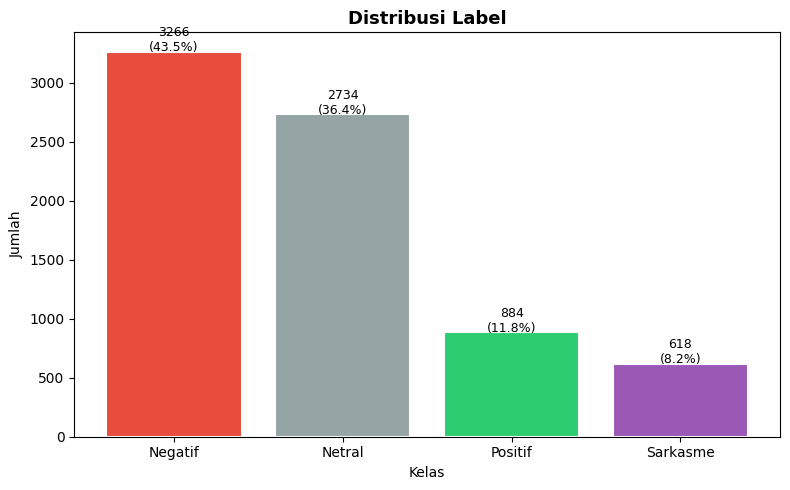

In [16]:
LC   = [COLORS[LABEL_NAMES[i]] for i in range(4)]
cnts = [(df['label']==k).sum() for k in range(4)]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(CLASS_NAMES, cnts, color=LC, edgecolor='white', linewidth=1.5)
ax.set_title('Distribusi Label', fontweight='bold', fontsize=13)
ax.set_xlabel('Kelas'); ax.set_ylabel('Jumlah')
for bar, v in zip(bars, cnts):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
            f'{v}\n({v/len(df):.1%})', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('eda_distribusi_label.png', dpi=150, bbox_inches='tight')
plt.show()

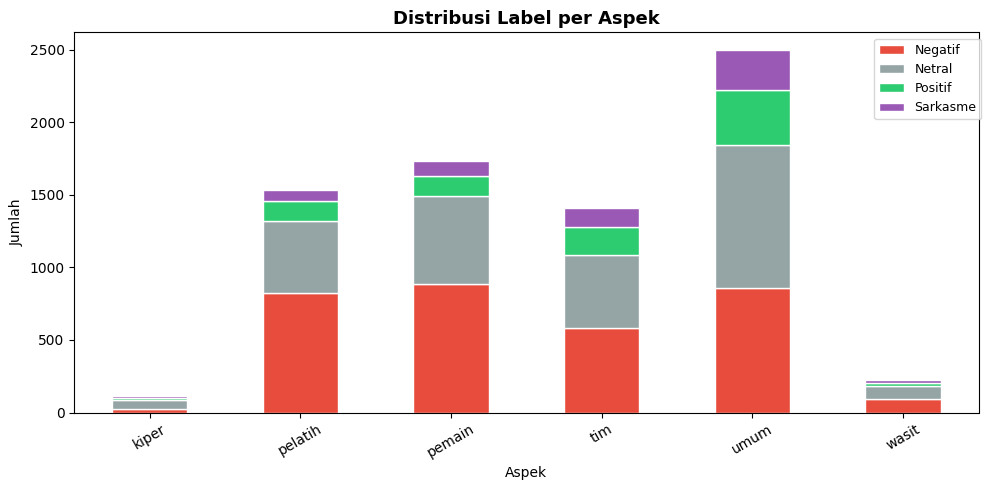

In [17]:
LC      = [COLORS[LABEL_NAMES[i]] for i in range(4)]
asp_lbl = df.groupby(['aspek','label']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
asp_lbl.plot(kind='bar', stacked=True, ax=ax,
             color=LC, edgecolor='white', legend=False)
ax.set_title('Distribusi Label per Aspek', fontweight='bold', fontsize=13)
ax.set_xlabel('Aspek'); ax.set_ylabel('Jumlah')
ax.tick_params(axis='x', rotation=30)
ax.legend([LABEL_NAMES[i] for i in range(4)], fontsize=9,
          bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig('eda_label_per_aspek.png', dpi=150, bbox_inches='tight')
plt.show()

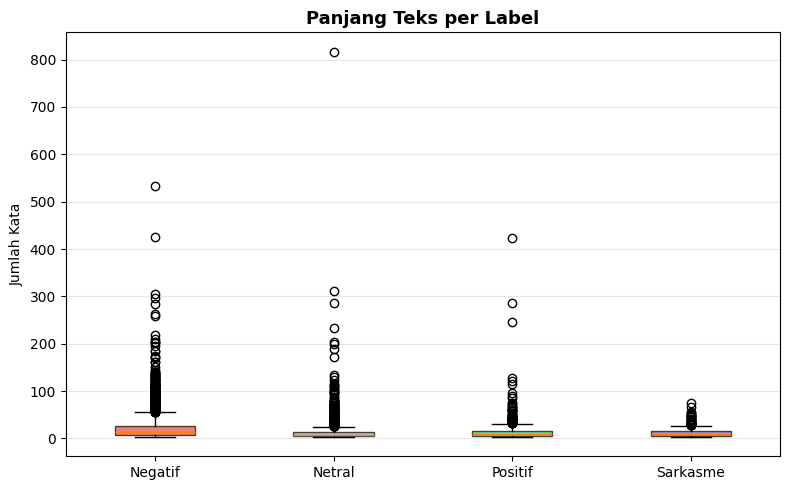

In [18]:
LC       = [COLORS[LABEL_NAMES[i]] for i in range(4)]
data_box = [df[df['label']==k]['text_clean'].str.split().str.len().values
            for k in range(4)]

fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot(data_box, patch_artist=True, labels=CLASS_NAMES)
for patch, color in zip(bp['boxes'], LC):
    patch.set_facecolor(color); patch.set_alpha(0.7)
ax.set_title('Panjang Teks per Label', fontweight='bold', fontsize=13)
ax.set_ylabel('Jumlah Kata')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('eda_panjang_per_label.png', dpi=150, bbox_inches='tight')
plt.show()

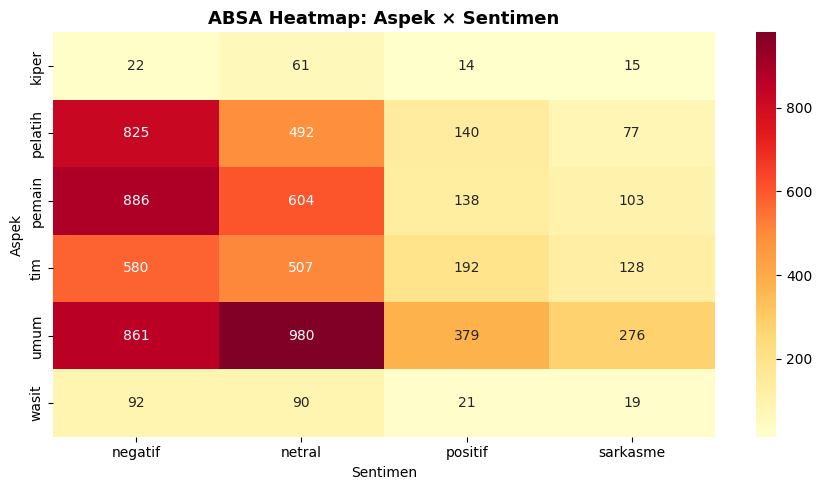

In [19]:
absa_pivot_eda = df.groupby(['aspek','absa_sentimen']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(absa_pivot_eda, annot=True, fmt='d', cmap='YlOrRd', ax=ax,
            cbar=True, annot_kws={'size': 10})
ax.set_title('ABSA Heatmap: Aspek × Sentimen', fontweight='bold', fontsize=13)
ax.set_xlabel('Sentimen'); ax.set_ylabel('Aspek')
plt.tight_layout()
plt.savefig('eda_absa_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

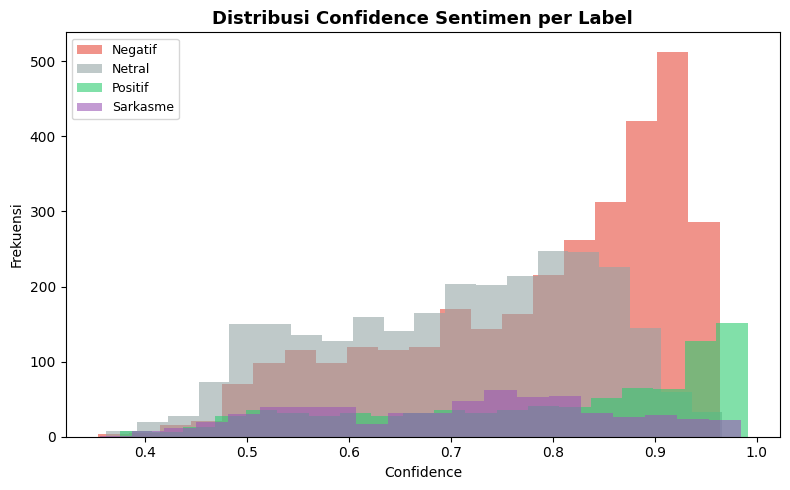

In [20]:
LC = [COLORS[LABEL_NAMES[i]] for i in range(4)]

fig, ax = plt.subplots(figsize=(8, 5))
for k, lbl in LABEL_NAMES.items():
    subset = df[df['label']==k]['sent_conf']
    ax.hist(subset, bins=20, alpha=0.6, label=lbl, color=LC[k])
ax.set_title('Distribusi Confidence Sentimen per Label', fontweight='bold', fontsize=13)
ax.set_xlabel('Confidence'); ax.set_ylabel('Frekuensi')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('eda_confidence_sentimen.png', dpi=150, bbox_inches='tight')
plt.show()

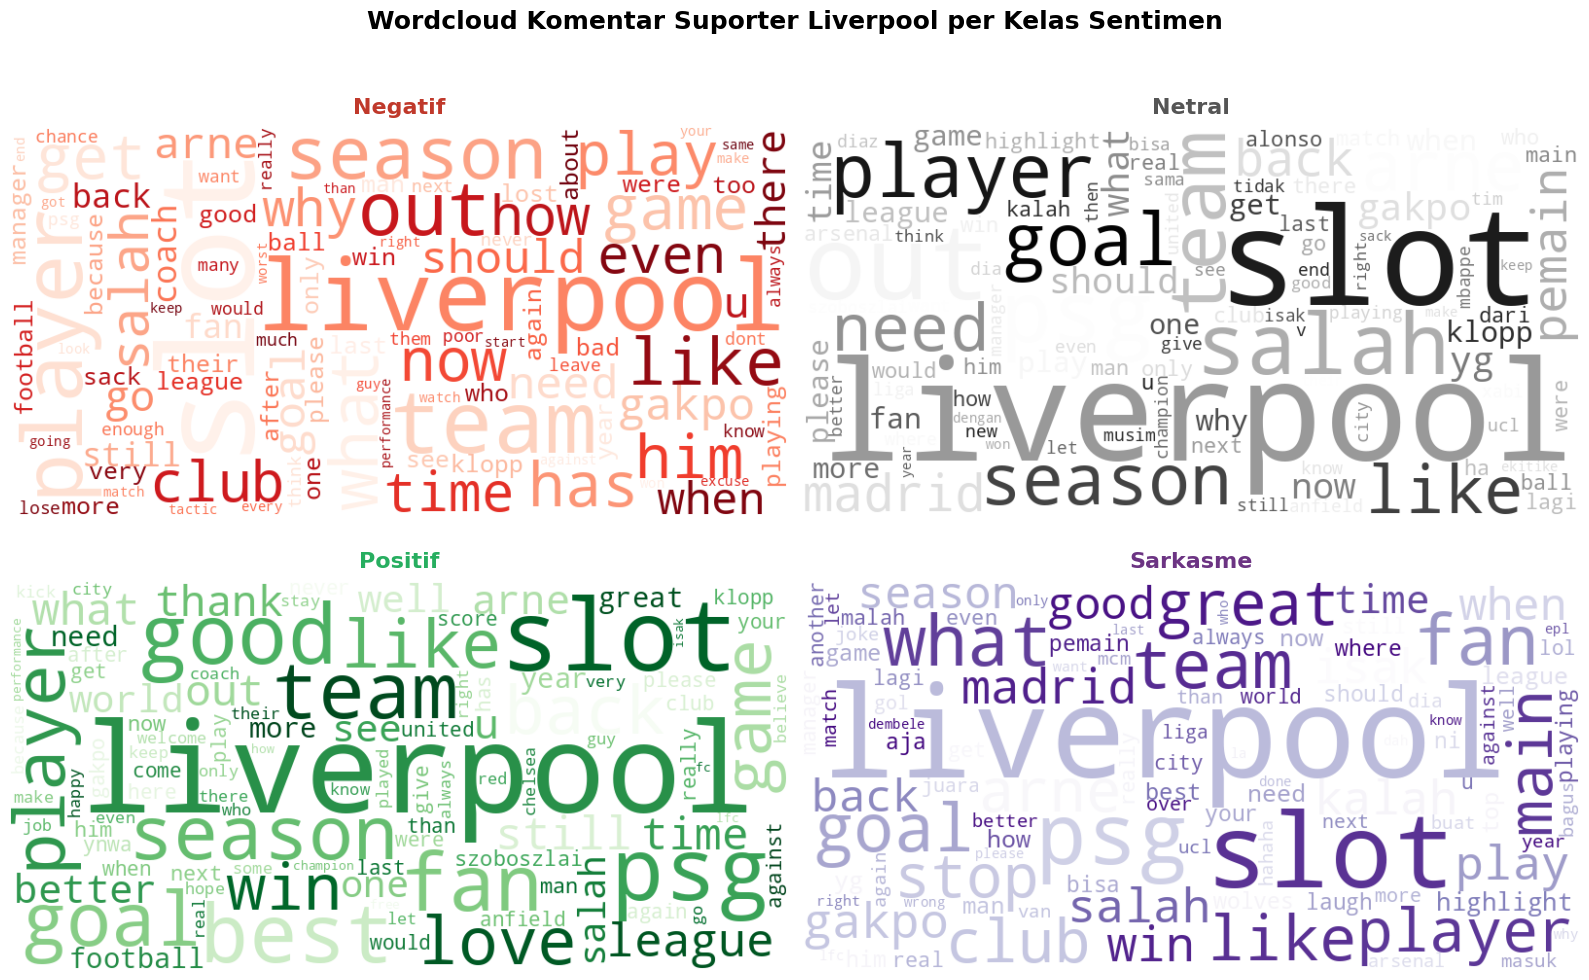

In [21]:
import re as _re2

def clean_wc(text):
    return _re2.sub(r'[^a-zA-Z\s]', '', str(text).lower())

STOPWORDS_WC = set(STOPWORDS) | {
    'the','a','an','is','it','in','on','to','of','and','i','was','for',
    'at','be','this','that','with','are','have','you','we','he','she',
    'they','my','me','his','her','our','not','no','but','so','if','or',
    'as','do','did','had','can','will','just','up','by','from','all',
    'yang','di','dan','ini','itu','ke','ada','nya','ya','ga','gak','udah',
    'im','its','been','s','t','re','ve','ll','d','m','don','doesn',
}

COLOR_MAP_WC = {'Negatif':'Reds','Netral':'Greys','Positif':'Greens','Sarkasme':'Purples'}
TITLE_COLOR  = {'Negatif':'#C0392B','Netral':'#555555','Positif':'#27AE60','Sarkasme':'#6C3483'}

texts_wc = {}
for lbl, name in LABEL_NAMES.items():
    subset = df[df['label'] == lbl]['text_clean'].dropna()
    texts_wc[name] = ' '.join(subset.apply(clean_wc))

# ── Wordcloud 2×2 grid (4 kelas) ──
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, (name, text) in enumerate(texts_wc.items()):
    wc = WordCloud(
        width=800, height=400,
        background_color='white',
        colormap=COLOR_MAP_WC[name],
        stopwords=STOPWORDS_WC,
        max_words=100,
        min_font_size=10,
        collocations=False,
    ).generate(text)
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].axis('off')
    axes[i].set_title(name, fontsize=16, fontweight='bold',
                      pad=10, color=TITLE_COLOR[name])

plt.suptitle('Wordcloud Komentar Suporter Liverpool per Kelas Sentimen',
             fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('wordcloud_4kelas.png', dpi=200, bbox_inches='tight')
plt.show()

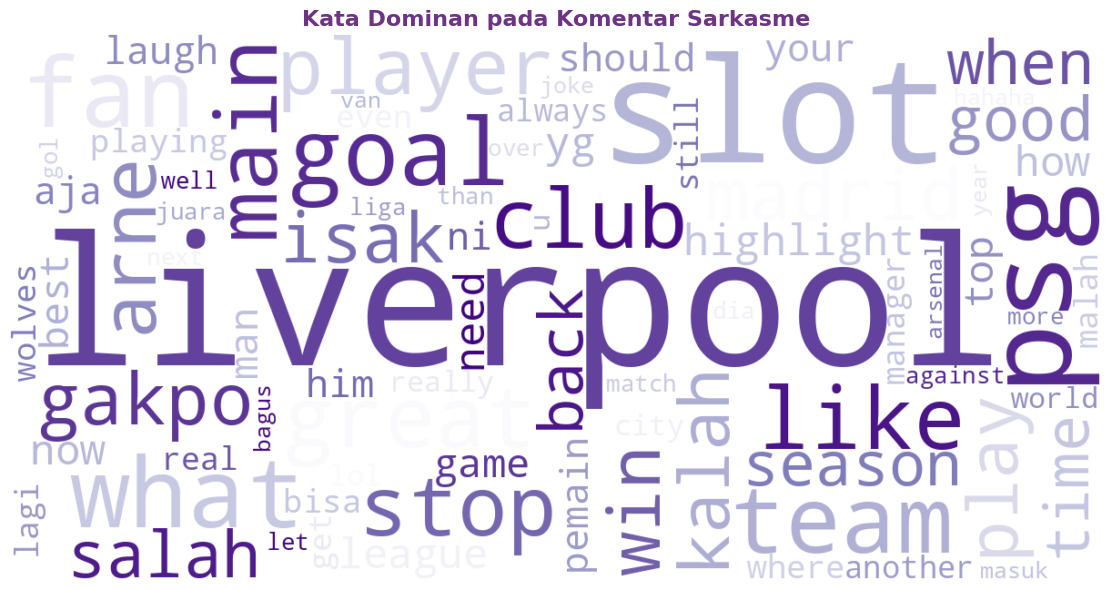

In [22]:
fig, ax = plt.subplots(figsize=(12, 6))
wc_sarc = WordCloud(
    width=1200, height=600,
    background_color='white',
    colormap='Purples',
    stopwords=STOPWORDS_WC,
    max_words=80,
    min_font_size=12,
    collocations=False,
    prefer_horizontal=0.8,
).generate(texts_wc['Sarkasme'])

ax.imshow(wc_sarc, interpolation='bilinear')
ax.axis('off')
ax.set_title('Kata Dominan pada Komentar Sarkasme',
             fontsize=16, fontweight='bold', color='#6C3483')
plt.tight_layout()
plt.savefig('wordcloud_sarkasme.png', dpi=200, bbox_inches='tight')
plt.show()

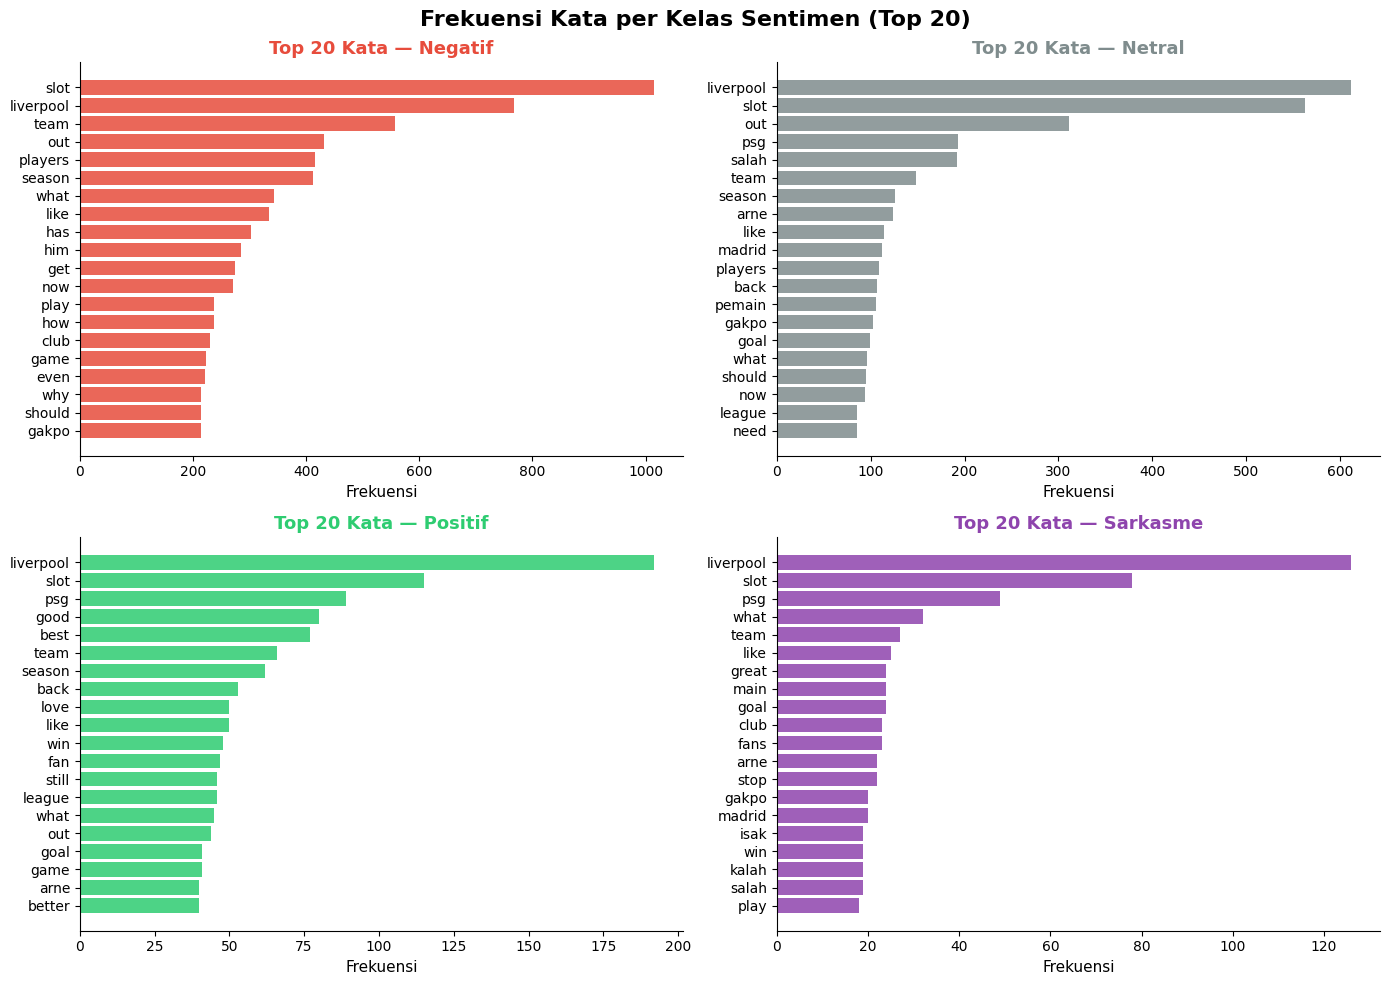

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
bar_colors = {'Negatif':'#E74C3C','Netral':'#7F8C8D',
              'Positif':'#2ECC71','Sarkasme':'#8E44AD'}

for i, (name, text) in enumerate(texts_wc.items()):
    words = [w for w in text.split()
             if w not in STOPWORDS_WC and len(w) > 2]
    top20 = Counter(words).most_common(20)
    words_list, counts = zip(*top20)
    axes[i].barh(words_list[::-1], counts[::-1],
                 color=bar_colors[name], alpha=0.85)
    axes[i].set_title(f'Top 20 Kata — {name}',
                      fontsize=13, fontweight='bold', color=bar_colors[name])
    axes[i].set_xlabel('Frekuensi', fontsize=11)
    axes[i].tick_params(axis='y', labelsize=10)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

plt.suptitle('Frekuensi Kata per Kelas Sentimen (Top 20)',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('top20_kata_per_kelas.png', dpi=200, bbox_inches='tight')
plt.show()

In [24]:
# ── ABSA: satu kalimat bisa punya BANYAK aspek dengan sentimen berbeda ──────
ASPECT_KEYWORDS = {
    'pemain': [
        'salah','van dijk','konate','gakpo','diaz','darwin','nunez',
        'mcallister','mamardashvili','frimpong','kerkez','wirtz','alonso',
        'trent','robertson','jones','szoboszlai','mac allister','player',
        'striker','midfielder','defender','forward','winger','captain',
        'pemain','striker','bek','penyerang','gelandang',
    ],
    'pelatih': [
        'slot','klopp','arne','manager','coach','gaffer','tactical',
        'tactic','formation','formasi','pelatih','manajer','taktik',
        'substitution','lineup','starting','bench',
    ],
    'wasit': [
        'referee','ref','var','offside','penalty','penalti','card',
        'kartu','foul','handball','decision','keputusan','wasit',
        'red card','yellow card','kartu merah','kartu kuning',
    ],
    'tim': [
        'liverpool','lfc','reds','kop','anfield','squad','team','club',
        'transfer','board','management','fsg','owners','tim','klub',
        'signing','contract','preseason',
    ],
    'kiper': [
        'goalkeeper','gk','keeper','mamardashvili','alisson','save',
        'clean sheet','cleansheet','kiper','penjaga gawang',
    ],
}

NEGATION_WORDS = [
    'not','no','never','without','lack','poor','bad','terrible',
    'awful','worst','horrible','disaster','embarrassing','shameful',
    'tidak','bukan','tanpa','kurang','buruk','jelek','parah',
]

POSITIVE_WORDS = [
    'great','brilliant','amazing','fantastic','outstanding','excellent',
    'superb','wonderful','incredible','magnificent','sensational','class',
    'good','best','perfect','top','love','proud','impressed',
    'bagus','hebat','luar biasa','keren','mantap','bangga','terbaik',
]

NEGATIVE_WORDS = [
    'terrible','awful','horrible','disaster','embarrassing','shameful',
    'poor','bad','worst','useless','pathetic','disgrace','sack','fire',
    'buruk','jelek','parah','memalukan','hancur','gagal','kalah','bobol',
]

SARCASM_SIGNALS = [
    'great job losing','brilliant defending','outstanding coach lost',
    'amazing defending conceded','top class goalkeeper conceded',
    'world class squad struggling','genius transfer','typical performance',
    'clearly working','as always sadly','masterclass in how to lose',
    'hebat banget kalah','luar biasa bobol','keren banget gagal',
    'mantap kalah','brilian kalah','jago banget kalah',
]

def detect_multi_aspect_sentiment(text, predicted_label):
    """
    Deteksi multiple aspek dalam satu kalimat beserta sentimen per aspek.
    Returns list of (aspek, sentimen) tuples.
    """
    tl    = text.lower()
    found = []

    # Cek apakah kalimat mengandung sinyal sarkasme
    is_sarcasm = (predicted_label == 3)

    for aspect, keywords in ASPECT_KEYWORDS.items():
        if not any(kw in tl for kw in keywords):
            continue

        # Cari window konteks sekitar keyword aspek (±5 kata)
        words = tl.split()
        aspect_positions = []
        for j, word in enumerate(words):
            if any(kw in word for kw in keywords):
                aspect_positions.append(j)

        if not aspect_positions:
            continue

        # Ambil konteks di sekitar posisi aspek
        context_words = set()
        for pos in aspect_positions:
            start = max(0, pos - 5)
            end   = min(len(words), pos + 6)
            context_words.update(words[start:end])

        # Tentukan sentimen per aspek
        if is_sarcasm:
            # Sarkasme selalu override ke sarkasme
            sentiment = 'sarkasme'
        else:
            has_pos = any(pw in context_words for pw in POSITIVE_WORDS)
            has_neg = any(nw in context_words for nw in NEGATIVE_WORDS)
            has_neg_signal = any(sig in tl for sig in NEGATION_WORDS)

            if has_pos and has_neg:
                # Konflik → ikut label utama
                if predicted_label == 0:   sentiment = 'negatif'
                elif predicted_label == 2: sentiment = 'positif'
                else:                      sentiment = 'netral'
            elif has_pos:
                sentiment = 'positif'
            elif has_neg or has_neg_signal:
                sentiment = 'negatif'
            else:
                # Default ke label utama
                if predicted_label == 0:   sentiment = 'negatif'
                elif predicted_label == 2: sentiment = 'positif'
                elif predicted_label == 3: sentiment = 'sarkasme'
                else:                      sentiment = 'netral'

        found.append((aspect, sentiment))

    # Kalau tidak ada aspek spesifik → aspek umum
    if not found:
        if predicted_label == 0:   sentiment = 'negatif'
        elif predicted_label == 2: sentiment = 'positif'
        elif predicted_label == 3: sentiment = 'sarkasme'
        else:                      sentiment = 'netral'
        found.append(('umum', sentiment))

    return found

print("Menerapkan ABSA ke seluruh dataset...")
absa_records = []

for idx, row in tqdm(df.iterrows(), total=len(df), desc='ABSA'):
    results = detect_multi_aspect_sentiment(row['text_clean'], row['label'])
    for aspect, sentiment in results:
        absa_records.append({
            'text_clean':     row['text_clean'],
            'label':          row['label'],
            'sentimen_utama': LABEL_NAMES[row['label']],
            'aspek':          aspect,
            'absa_sentimen':  sentiment,
        })

df_absa = pd.DataFrame(absa_records)
df['absa_results'] = df.apply(
    lambda r: detect_multi_aspect_sentiment(r['text_clean'], r['label']), axis=1
)

print(f"\nTotal record ABSA : {len(df_absa):,}")
print(f"Rata-rata aspek   : {len(df_absa)/len(df):.2f} per kalimat")
print(f"\nDistribusi Aspek:\n{df_absa['aspek'].value_counts().to_string()}")
print(f"\nDistribusi Sentimen ABSA:\n{df_absa['absa_sentimen'].value_counts().to_string()}")

df_absa.to_csv('dataset_absa.csv', index=False)
print("\nDisimpan ke dataset_absa.csv")

Menerapkan ABSA ke seluruh dataset...


ABSA:   0%|          | 0/7502 [00:00<?, ?it/s]


Total record ABSA : 9,985
Rata-rata aspek   : 1.33 per kalimat

Distribusi Aspek:
aspek
tim        2824
umum       2415
pelatih    2258
pemain     1815
wasit       373
kiper       300

Distribusi Sentimen ABSA:
absa_sentimen
negatif     5400
netral      2635
positif     1216
sarkasme     734

Disimpan ke dataset_absa.csv


In [25]:
print('='*65)
print('ABSA — Aspect-Based Sentiment Analysis (Multi-Aspek)')
print('='*65)

absa_pivot = df_absa.groupby(['aspek','absa_sentimen']).size().unstack(fill_value=0)
for col in ['negatif','netral','positif','sarkasme']:
    if col not in absa_pivot.columns:
        absa_pivot[col] = 0
absa_pivot = absa_pivot[['negatif','netral','positif','sarkasme']]
absa_pivot['TOTAL'] = absa_pivot.sum(axis=1)
print(absa_pivot.to_string())
print('='*65)
print(f"TOTAL: {absa_pivot['TOTAL'].sum():,}")

# Contoh multi-aspek
print('\n=== CONTOH KALIMAT MULTI-ASPEK ===\n')
multi_texts = df_absa.groupby('text_clean').filter(lambda x: len(x) > 1)
for txt, grp in list(multi_texts.groupby('text_clean'))[:5]:
    print(f'Teks  : {txt[:80]}')
    print(f'Label : {LABEL_NAMES[grp["label"].iloc[0]]}')
    for _, r in grp.iterrows():
        print(f'  → {r["aspek"]:<10}: {r["absa_sentimen"]}')
    print()

ABSA — Aspect-Based Sentiment Analysis (Multi-Aspek)
absa_sentimen  negatif  netral  positif  sarkasme  TOTAL
aspek                                                   
kiper              137      93       42        28    300
pelatih           1455     489      211       103   2258
pemain            1056     432      222       105   1815
tim               1688     595      345       196   2824
umum               832     953      358       272   2415
wasit              232      73       38        30    373
TOTAL: 9,985

=== CONTOH KALIMAT MULTI-ASPEK ===

Teks  : -Assume there s a critical need for defence coordination/upgrade. -Didn t fully 
Label : Negatif
  → pemain    : negatif
  → pelatih   : negatif
  → kiper     : negatif

Teks  : . Already MENTIONED, LFC will OUT on this season UCL as a well as the next seaso
Label : Negatif
  → pelatih   : negatif
  → tim       : negatif

Teks  : 0 shoot on target. That’s Slot’s Liverpool.
Label : Negatif
  → pelatih   : negatif
  → tim       : n

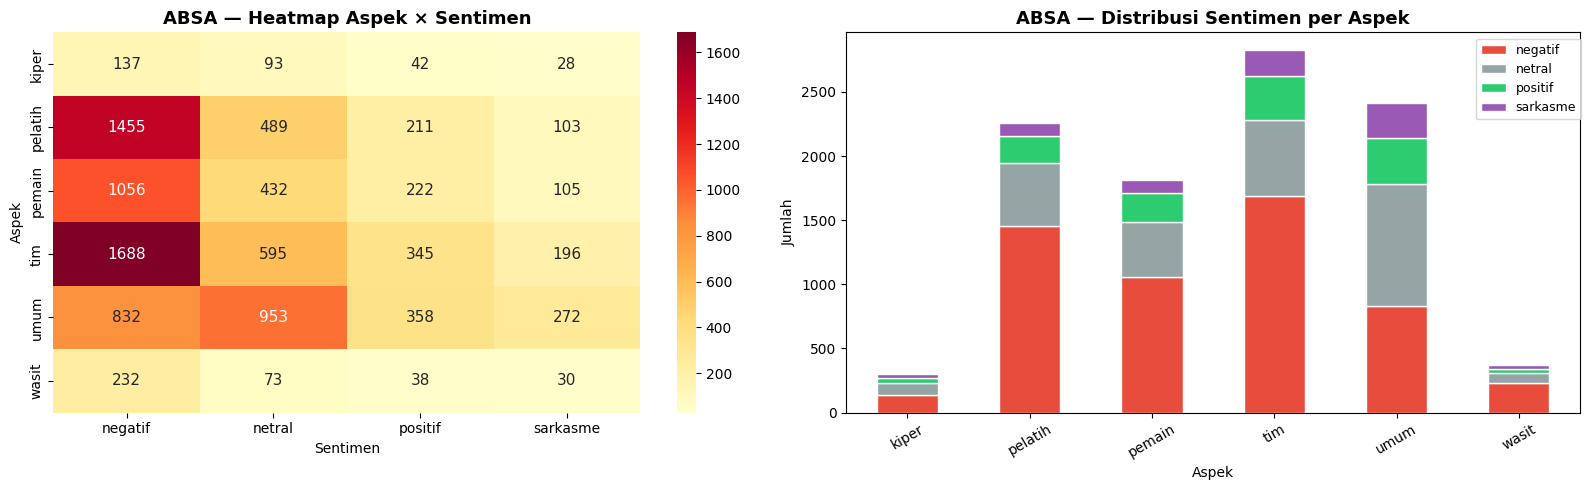

In [26]:
SENT_COLORS = {'negatif':'#e74c3c','netral':'#95a5a6',
               'positif':'#2ecc71','sarkasme':'#9b59b6'}
pivot_plot = absa_pivot.drop(columns='TOTAL', errors='ignore')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Heatmap
sns.heatmap(pivot_plot, annot=True, fmt='d', cmap='YlOrRd',
            ax=axes[0], annot_kws={'size':11}, cbar=True)
axes[0].set_title('ABSA — Heatmap Aspek × Sentimen', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Sentimen'); axes[0].set_ylabel('Aspek')

# Stacked bar
pivot_plot.plot(kind='bar', stacked=True, ax=axes[1],
                color=[SENT_COLORS[c] for c in pivot_plot.columns],
                edgecolor='white')
axes[1].set_title('ABSA — Distribusi Sentimen per Aspek', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Aspek'); axes[1].set_ylabel('Jumlah')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(bbox_to_anchor=(1.01,1), fontsize=9)

plt.tight_layout()
plt.savefig('absa_combined.png', dpi=150, bbox_inches='tight')
plt.show()

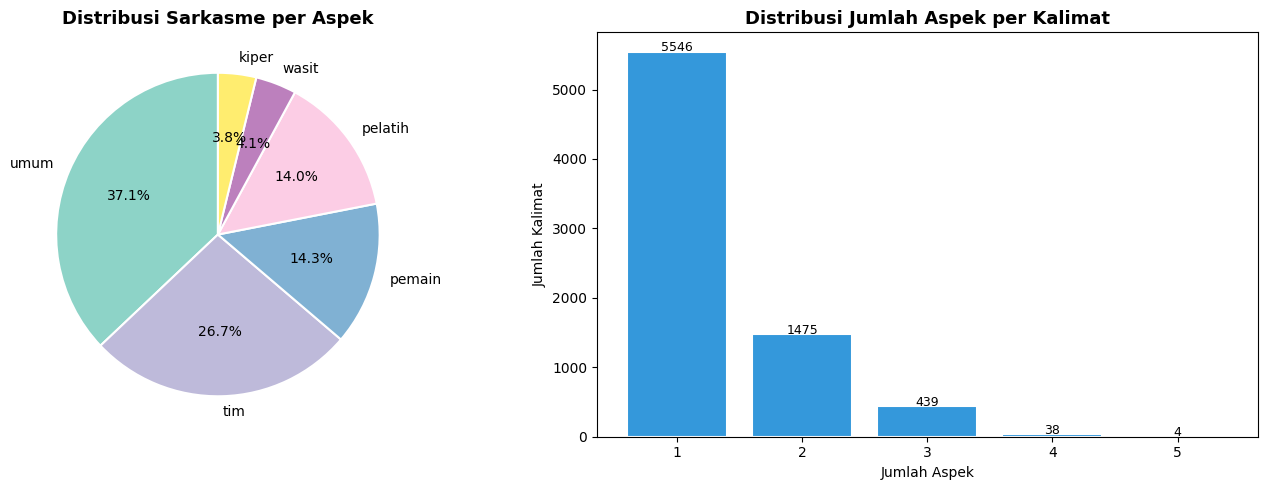

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie sarkasme per aspek
sarc_per_asp = df_absa[df_absa['absa_sentimen']=='sarkasme']['aspek'].value_counts()
if len(sarc_per_asp) > 0:
    axes[0].pie(sarc_per_asp.values, labels=sarc_per_asp.index,
                autopct='%1.1f%%',
                colors=plt.cm.Set3(np.linspace(0,1,len(sarc_per_asp))),
                startangle=90, wedgeprops={'edgecolor':'white','linewidth':1.5})
    axes[0].set_title('Distribusi Sarkasme per Aspek', fontweight='bold', fontsize=13)

# Jumlah aspek per kalimat
n_aspects_raw = df_absa.groupby('text_clean').size()
aspect_counts = n_aspects_raw.value_counts().sort_index()
bars = axes[1].bar(aspect_counts.index.astype(str), aspect_counts.values,
                   color='#3498db', edgecolor='white', linewidth=1.5)
axes[1].set_title('Distribusi Jumlah Aspek per Kalimat', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Jumlah Aspek'); axes[1].set_ylabel('Jumlah Kalimat')
for bar, v in zip(bars, aspect_counts.values):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
                 f'{v}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('absa_pie_multi.png', dpi=150, bbox_inches='tight')
plt.show()

In [28]:
AUG_TEXTS = {
    0: [
        "Liverpool played absolutely terrible tonight, no desire at all",
        "Slot has no idea what he is doing, the tactics are a complete mess",
        "That was an embarrassing defeat, the players should be ashamed",
        "Van Dijk was nowhere to be seen, disgraceful performance",
        "Sack Slot now, this team is going nowhere under him",
        "Worst Liverpool performance in years, completely spineless",
        "The team has no identity, no shape, no fight whatsoever",
        "We lost to a team that was bottom of the table, absolutely shameful",
        "Salah is finished, he has been terrible all season",
        "Liverpool defence is a complete disaster, no organisation",
        "wasit parah banget keputusannya tidak adil",
        "pemain kita bermain sangat buruk malam ini tanpa semangat",
        "pelatih harus dipecat taktiknya kacau dan tidak ada rencana",
        "tim kita kalah memalukan malam ini lagi dan lagi",
        "pertahanan kita bobol terus tidak ada perbaikan sama sekali",
        "another szoboszlai freekick, another terrible performance",
        "stop changing the formation every single week, ridiculous",
        "adding isak right now would be waste of time and money",
        "another game another disappointment from this squad",
        "week in week out always the same mistakes being made",
        "another loss another excuse from the manager, tired of it",
        "stop with the constant rotation it is killing our momentum",
        "another poor display another 3 points dropped at home",
        "i knew it this signing would be a waste of money",
        "stop changing defenders every week it makes no sense",
        "wow 3 goals conceded at home, this is unacceptable",
        "wow what is going on with this team, absolutely shocking",
        "damn what is happening to this squad lately",
        "damn that was awful, completely fell apart in second half",
        "wow we just lost to the worst team in the league",
        "damn slot machine has stopped working, no ideas at all",
        "wow how did we concede that, absolutely terrible defending",
        "damn what a poor performance, no fight no desire",
        "wow 4 goals conceded, where was the defence tonight",
        "damn this team has completely fallen apart this season",
        "slot machine has stopped working, time for a change",
        "slot machine broken, same result every single week",
        "wow conceding 3 at home again, embarrassing for this club",
        "damn we are in serious trouble this season",
        "wow that was genuinely one of the worst halves i have seen",
    ],
    1: [
        "The match ended 1-1 at Anfield tonight",
        "Liverpool face Chelsea next weekend in the Premier League",
        "Slot made three substitutions in the second half",
        "The referee awarded a penalty in the 78th minute",
        "Liverpool currently sit 4th in the Premier League table",
        "The match is scheduled for Saturday at 3pm",
        "Salah scored his 15th goal of the season tonight",
        "Liverpool drew 0-0 in a tight game at Old Trafford",
        "pertandingan berlangsung selama 90 menit penuh",
        "liverpool bermain imbang malam ini di anfield",
        "pelatih slot melakukan pergantian pemain di babak kedua",
        "skor akhir pertandingan adalah 2-2",
        "pertandingan dijadwalkan hari sabtu pukul 8 malam",
        "liverpool menghadapi chelsea di pertandingan berikutnya",
        "pemain baru telah resmi bergabung dengan liverpool",
        "tensions in the squad are normal at any big club",
        "this kind of argument happens at every club regularly",
        "ce genre de tensions entre coequipiers est assez frequent",
        "les joueurs ont besoin de plus de cohesion entre eux",
        "the players had a disagreement but it happens everywhere",
        "both teams played well and deserved a point each",
        "the stats show liverpool had 60 percent possession tonight",
        "slot confirmed the injury in the post match press conference",
        "cole palmer getting sus on the thumbnail",
        "the thumbnail for this video is very suspicious",
        "that thumbnail edit was really something else entirely",
        "bro the thumbnail got me clicking immediately lol",
        "why does the thumbnail look like that honestly",
        "the editor went crazy with this thumbnail today",
        "thumbnail is wild but the content is good",
        "the video title and thumbnail do not match at all",
    ],
    2: [
        "What a performance from Liverpool tonight, absolutely outstanding",
        "Salah was unplayable today, world class player",
        "That was a brilliant win, the team looked incredible",
        "Slot is doing an amazing job, tactically very impressive",
        "The whole squad was magnificent, so proud to be a Liverpool fan",
        "Van Dijk was a rock at the back, fantastic performance",
        "Liverpool are back to their best, what a team",
        "That goal from Salah was absolutely sensational",
        "pemain kita bermain luar biasa malam ini",
        "kemenangan yang sangat memuaskan untuk liverpool",
        "pelatih slot membuat keputusan taktik yang sangat bagus",
        "bangga sekali jadi fans liverpool melihat penampilan tadi",
        "gol yang indah dari salah benar benar memukau",
        "tim bermain dengan semangat yang luar biasa malam ini",
        "pertahanan sangat kokoh tidak ada celah untuk lawan",
        "konate s challenge blown my mind, top class tackle",
        "wonderful goal, what a strike from distance",
        "world class save from the goalkeeper, incredible reflexes",
        "top class performance, genuinely impressed tonight",
        "what a wonderful goal, bad luck it was offside",
        "everyone was saying he was finished but what a player",
        "blown my mind with that performance, truly special",
        "world class decision making under pressure tonight",
        "everyone saying he is world class and he proved it tonight",
        "lol what a goal from salah, absolute class player",
        "top class tackle from konate, saved us there",
        "wonderful finish, bad luck the flag was up",
        "world class goalkeeper performance, kept us in the game",
        "everyone doubted him but he delivered world class tonight",
        "everyone saying ekitike and wirtz are world class last week lol",
        "everyone doubted him last week but look at him now lol",
        "people were saying he was finished but lol what a player",
        "everyone wrote him off last month lol he proved them wrong",
        "lol everyone said he was bad but he just scored a brace",
        "everyone saying the team is bad lol we just won 4-0",
        "lol people said slot was finished but look at this result",
        "everyone calling for his head last week lol aging like milk",
    ],
    3: [
        "wow great job losing at home again, truly world class team",
        "brilliant defending, only conceded 4 in the first half",
        "outstanding coach, lost 10 in a row, absolute genius",
        "amazing defending, only let in 5 goals, world class",
        "top class goalkeeper, conceded from every single shot",
        "superb display, thoroughly deserved to lose that one",
        "world class squad, struggling against relegation candidates",
        "incredible consistency, losing to bottom half clubs of course",
        "genius transfer policy, clearly working wonders right",
        "what a result, typical performance as always sadly",
        "brilliant performance as usual, another embarrassing defeat",
        "great tactics Slot, clearly working perfectly as always",
        "amazing work as always, typical liverpool moment",
        "brilliant as usual, conceding in the last minute again",
        "great job once again, making the same mistakes obviously",
        "what a legend Slot is, lost again in typical fashion",
        "best performance of the season, absolutely terrible",
        "fantastic result, couldn't be more proud of this disaster",
        "incredible work rate, they barely even tried tonight",
        "so proud of this squad, embarrassing themselves once again",
        "love how we keep conceding the same way, so creative",
        "nice to see the same old mistakes, at least we're consistent",
        "really enjoying watching us lose every week, fantastic entertainment",
        "great to see Slot learning nothing from last week, refreshing",
        "love the way we just gave that goal away, such generosity",
        "wonderful to see our world class defending on display again",
        "thrilling stuff, conceding in the 90th minute again obviously",
        "magnificent team effort, everyone contributed to that defeat",
        "brilliant from start to finish, a masterclass in how to lose",
        "sensational performance, set a new record for most goals conceded",
        "what a joy, conceding in injury time as usual, so reliable",
        "truly inspiring, same formation same result, genius coaching",
        "outstanding vision from Slot, clearly sees things we don't",
        "wow amazing, another clean sheet for the opposition goalkeeper",
        "fantastic mentality, giving up leads in the last 5 minutes always",
        "incredible squad depth, all of them equally bad tonight",
        "great to see the team pressing high, straight into their net",
        "beautiful football, losing to a 10 man team is an art form",
        "world class club, can't even beat teams with 9 points all season",
        "lovely stuff, defending corners as badly as ever, consistent",
        "brilliant communication between the defenders, zero apparently",
        "stunning performance, three goals down in 20 minutes, wow",
        "amazing squad management, rotating into a 5-0 loss, genius",
        "what a pressing game, pressed straight into our own goal",
        "wonderful transition play, from defence directly to disaster",
        "fantastic game plan, Slot clearly prepared well for this one",
        "superb team spirit, all 11 players equally invisible tonight",
        "this is getting really bad",
        "boring to watch this team every week",
        "arne slot stay, just kidding please leave",
        "slot out please, we beg you",
        "same old liverpool, same old excuses",
        "nothing changes here does it",
        "here we go again, typical",
        "what a surprise, not really",
        "as expected, disappointment as usual",
        "classic liverpool moment right there",
        "slot stay, surely you are joking",
        "waiting for this team to improve, still waiting",
        "another day another disaster from this club",
        "slot is the answer, to what question exactly",
        "remove slot, simple as that",
        "goalkeeper skill is great 😂😂",
        "andy carroll had another great game 🤣",
        "world class performance as always 😂",
        "brilliant defending once again 🤣🤣",
        "slot is a genius 😂😂😂",
        "what a result 😂 truly deserved",
        "outstanding team 🤣 absolutely outstanding",
        "great tactics from slot 😂 as always",
        "what a save 🤣 into his own net",
        "top class goalkeeper 😂 let in 4 goals",
        "incredible work rate 🤣 barely tried tonight",
        "such a great team 😂 losing again",
        "love this club 🤣 embarrassing us weekly",
        "world class squad 😂 struggling as usual",
        "fantastic result 🤣 couldn't make this up",
        "hebat banget kalah terus emang juara memang",
        "luar biasa sekali bobol lagi seperti biasa",
        "keren banget ya gagal lagi di pertandingan penting",
        "mantap pelatihnya taktiknya kacau tapi tetap dipercaya",
        "brilian memang tim kita kalah dari tim juru kunci",
        "jago banget sih kalah lagi lagi dan lagi",
        "bagus banget pertahanannya bobol terus setiap pertandingan",
        "terbaik memang kebobolan terus malam ini",
        "top banget performa malam ini memalukan sekali",
        "keren banget ya dipecat juga akhirnya emang sudah kuduga",
        "juara memang tim kita kalah di kandang sendiri lagi",
        "mantap banget bobol lagi seperti biasa emang jago",
        "senang banget lihat tim kita bobol lagi, konsisten sekali",
        "keren ya selalu kalah di momen penting, sudah tradisi",
        "hebat banget sih pelatihnya, kalah terus tapi masih dipercaya",
        "luar biasa pertahanannya, bobol terus tanpa henti memang jago",
        "mantap banget ya kalah sama tim papan bawah, luar biasa",
        "bagus banget taktiknya, selalu gagal di momen krusial ya",
        "amazing banget liverpool, kebobolan lagi seperti biasa emang",
        "juara banget deh tim kita, hancur lagi malam ini",
        "wow hebat banget nih tim, kalah lagi sudah pasti",
        "luar biasa konsistennya, selalu kalah di laga penting",
        "keren sekali slot, taktiknya memang tidak ada habisnya gagalnya",
        "mantap betul pertahanannya, bobol dalam 5 menit lagi",
        "bagus sekali ya penampilan striker kita, tidak mencetak gol lagi",
        "top banget bek kita, tidur semua saat corner lawan",
        "hebat betul manajemennya, jual pemain bagus beli yang biasa saja",
        "mantap banget ya, sudah pasti kalah di laga derbi ini",
        "wow sungguh luar biasa, kebobolan dari tendangan sudut lagi",
        "hebat sekali pressing kita, langsung masuk gawang sendiri",
        "luar biasa mental pemain kita, unggul langsung panik sendiri",
        "keren banget sih slot, ganti formasi tapi hasilnya sama saja",
        "mantap sekali ya slot, rotasi pemain semua sama buruknya",
        "brilian memang slot ini, kalah dengan cara yang berbeda tiap kali",
        "top sekali defending kita malam ini, semua tidur di lini belakang",
    ],
}

AUG_COUNT = {0: 80, 1: 80, 2: 80, 3: 200}   # ← sarkasme dari 150 → 200
aug_rows  = []

for cls_idx, texts_aug in AUG_TEXTS.items():
    n = AUG_COUNT[cls_idx]
    # minimal duplikat: habiskan semua unik dulu, baru sample sisa
    if n <= len(texts_aug):
        chosen = random.sample(texts_aug, k=n)
    else:
        chosen  = texts_aug.copy()
        chosen += random.choices(texts_aug, k=n - len(texts_aug))
    random.shuffle(chosen)
    for t in chosen:
        aug_rows.append({
            'text_clean':    t,
            'aspek':         detect_aspect(t),
            'sentimen':      'negatif' if cls_idx in [0,3] else ('netral' if cls_idx==1 else 'positif'),
            'sarkasme':      1 if cls_idx == 3 else 0,
            'label':         cls_idx,
            'absa_sentimen': 'sarkasme' if cls_idx==3 else ('negatif' if cls_idx==0 else ('netral' if cls_idx==1 else 'positif')),
            'sent_conf':     0.8,
        })
    print(f'  +{n} sampel {LABEL_NAMES[cls_idx]}')

df_aug  = pd.DataFrame(aug_rows)
df_full = pd.concat([
    df[['text_clean','aspek','sentimen','sarkasme','label','absa_sentimen','sent_conf']],
    df_aug[['text_clean','aspek','sentimen','sarkasme','label','absa_sentimen','sent_conf']]
], ignore_index=True)

print(f'\nTotal setelah augmentasi: {len(df_full):,}')
print('\n=== DISTRIBUSI FINAL ===')
for k in [0,1,2,3]:
    v = (df_full['label']==k).sum()
    print(f'  {LABEL_NAMES[k]:<10}: {v:>5} ({v/len(df_full):.1%})')

df_full.to_csv('dataset_final.csv', index=False)
df = df_full.copy()

  +80 sampel Negatif
  +80 sampel Netral
  +80 sampel Positif
  +200 sampel Sarkasme

Total setelah augmentasi: 7,942

=== DISTRIBUSI FINAL ===
  Negatif   :  3346 (42.1%)
  Netral    :  2814 (35.4%)
  Positif   :   964 (12.1%)
  Sarkasme  :   818 (10.3%)


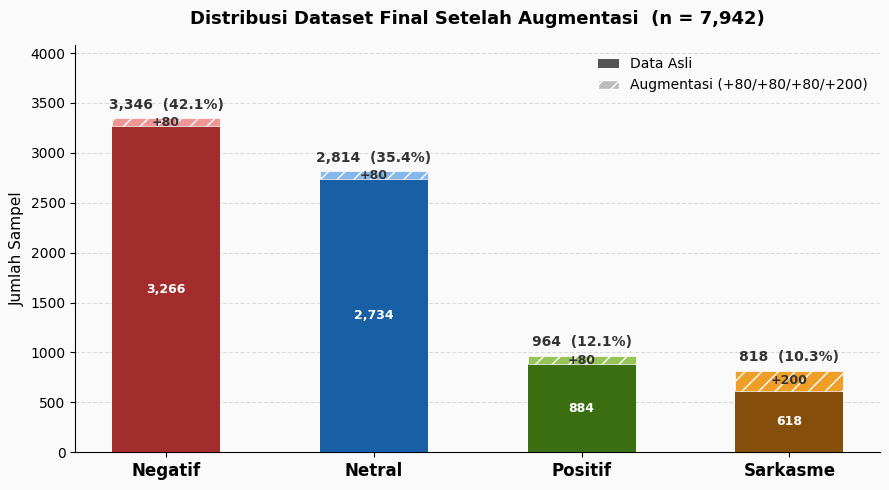

In [29]:
# ── Hitung distribusi ──────────────────────────────────────────────────────
final_dist  = df_full['label'].value_counts().sort_index()
orig_counts = {k: int(final_dist[k]) - AUG_COUNT[k] for k in range(4)}

labels    = [LABEL_NAMES[k] for k in range(4)]
orig_vals = np.array([orig_counts[k]  for k in range(4)])
aug_vals  = np.array([AUG_COUNT[k]    for k in range(4)])
totals    = orig_vals + aug_vals
total_all = int(totals.sum())

# ── Warna per kelas ────────────────────────────────────────────────────────
COLORS_DARK  = ['#A32D2D', '#185FA5', '#3B6D11', '#854F0B']
COLORS_LIGHT = ['#F09595', '#85B7EB', '#97C459', '#EF9F27']

# ── Plot ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor('#FAFAFA')
ax.set_facecolor('#FAFAFA')

x, w = np.arange(4), 0.52

b_orig = ax.bar(x, orig_vals, w, color=COLORS_DARK, zorder=3)
b_aug  = ax.bar(x, aug_vals,  w, bottom=orig_vals,
               color=COLORS_LIGHT, hatch='//',
               edgecolor='white', linewidth=0.5, zorder=3)

# ── Label total + persentase di atas bar ──────────────────────────────────
for i, (tot, bar) in enumerate(zip(totals, b_aug)):
    pct = tot / total_all * 100
    ax.text(i, tot + max(totals) * 0.02,
            f'{tot:,}  ({pct:.1f}%)',
            ha='center', va='bottom', fontsize=10,
            fontweight='bold', color='#333333')

# ── Count di dalam tiap segmen bar ────────────────────────────────────────
for i in range(4):
    if orig_vals[i] > 15:
        ax.text(i, orig_vals[i] / 2, f'{orig_vals[i]:,}',
                ha='center', va='center', fontsize=9,
                color='white', fontweight='bold')
    ax.text(i, orig_vals[i] + aug_vals[i] / 2, f'+{aug_vals[i]}',
            ha='center', va='center', fontsize=9,
            color='#333333', fontweight='bold')

# ── Styling ────────────────────────────────────────────────────────────────
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12, fontweight='bold')
ax.set_ylabel('Jumlah Sampel', fontsize=11)
ax.set_title(f'Distribusi Dataset Final Setelah Augmentasi  (n = {total_all:,})',
             fontsize=13, fontweight='bold', pad=15)
ax.set_ylim(0, max(totals) * 1.22)
ax.yaxis.grid(True, linestyle='--', alpha=0.4, zorder=0)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)

# ── Legend ─────────────────────────────────────────────────────────────────
aug_label = f'Augmentasi (+{AUG_COUNT[0]}/+{AUG_COUNT[1]}/+{AUG_COUNT[2]}/+{AUG_COUNT[3]})'
p1 = mpatches.Patch(facecolor='#555555', label='Data Asli')
p2 = mpatches.Patch(facecolor='#BBBBBB', hatch='//',
                    edgecolor='white', label=aug_label)
ax.legend(handles=[p1, p2], fontsize=10, loc='upper right',
          frameon=False, handlelength=1.5)

plt.tight_layout()
plt.show()

In [30]:
MAX_VOCAB   = 30000
MAX_SEQ_LEN = 120
EMBED_DIM   = 300
NUM_CLASSES = 4

# ── Ekspansi ABSA pada df yang sudah diaugmentasi (df = df_full dari Cell 23) ──
# Setiap komentar dipecah menjadi N sampel sesuai aspek yang terdeteksi
# Sehingga model benar-benar melakukan ABSA (aspect-conditioned sentiment)

SENT_STR2LABEL = {'negatif': 0, 'netral': 1, 'positif': 2, 'sarkasme': 3}

absa_model_records = []
for _, row in tqdm(df.iterrows(), total=len(df), desc='ABSA expansion'):
    text_clean = row['text_clean']
    gold_label = int(row['label'])
    absa_result = detect_multi_aspect_sentiment(text_clean, gold_label)
    for asp, sent_str in absa_result:
        lbl = SENT_STR2LABEL.get(sent_str.lower(), gold_label)
        absa_model_records.append({
            'text':   text_clean,
            'aspect': asp,
            'label':  lbl,
        })

df_model = pd.DataFrame(absa_model_records)
print(f'Dataset asli (post-augmentasi) : {len(df):,} komentar')
print(f'Dataset model (ABSA expanded)  : {len(df_model):,} sampel')
print(f'Rata-rata aspek per komentar   : {len(df_model)/len(df):.2f}')
print(f'\nDistribusi label setelah ekspansi:')
for k in [0,1,2,3]:
    v = (df_model['label']==k).sum()
    print(f'  {LABEL_NAMES[k]:<10}: {v:>6} ({v/len(df_model):.1%})')
print(f'\nDistribusi aspek:')
print(df_model['aspect'].value_counts().to_string())

# ── Vocabulary (tambahkan aspect tokens di depan) ──────────────────────────
all_words = []
for text in df_model['text']:
    all_words.extend(str(text).lower().split())

vocab      = ['<PAD>', '<UNK>'] + ASPECT_TOKENS + \
             [w for w, _ in Counter(all_words).most_common(MAX_VOCAB - 2 - len(ASPECT_TOKENS))]
word2idx   = {w: i for i, w in enumerate(vocab)}
VOCAB_SIZE = len(vocab)
print(f'\nVocabulary: {VOCAB_SIZE:,} (termasuk {len(ASPECT_TOKENS)} aspect tokens)')

# ── text_to_seq: token aspek disisipkan di posisi pertama ─────────────────
def text_to_seq(text, aspect='umum', max_len=MAX_SEQ_LEN):
    asp_token = ASPECT2TOKEN.get(aspect, '<ASP_UMUM>')
    asp_idx   = word2idx[asp_token]
    tokens    = str(text).lower().split()[:max_len - 1]  # -1 slot untuk aspect token
    seq       = [asp_idx] + [word2idx.get(t, 1) for t in tokens]
    return seq + [0] * (max_len - len(seq))

# ── Buat X dan y dari df_model (ABSA expanded) ────────────────────────────
X = np.array([text_to_seq(t, asp)
              for t, asp in zip(df_model['text'], df_model['aspect'])])
y = df_model['label'].values

# ── Load FastText ──────────────────────────────────────────────────────────
def load_fasttext(word2idx, embed_dim=300):
    import os
    matrix = np.random.normal(0, 0.1, (len(word2idx), embed_dim))
    matrix[0] = 0
    total_found = 0
    for fname in ['cc.en.300.vec', 'cc.id.300.vec']:
        if not os.path.exists(fname): continue
        print(f'Loading: {fname}')
        found = 0
        with open(fname, 'r', encoding='utf-8', errors='ignore') as f:
            next(f)
            for line in tqdm(f, total=2000000, desc=fname):
                parts = line.rstrip().split(' ')
                if parts[0] in word2idx and len(parts) > embed_dim:
                    vec = np.array(parts[1:embed_dim+1], dtype=np.float32)
                    if len(vec) == embed_dim:
                        matrix[word2idx[parts[0]]] = vec
                        found += 1
        print(f'  Coverage: {found:,}/{len(word2idx):,} ({found/len(word2idx):.1%})')
        total_found += found
    return torch.FloatTensor(matrix)

PRETRAINED_EMBEDDINGS = load_fasttext(word2idx)

# ── Train / Val / Test split ───────────────────────────────────────────────
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, random_state=SEED, stratify=y_tmp)

Xte_seq = X_test.copy()

print(f'\nTrain:{len(X_train):,} | Val:{len(X_val):,} | Test:{len(X_test):,}')
print(f'Sarkasme di test: {(y_test==3).sum()}')

ABSA expansion:   0%|          | 0/7942 [00:00<?, ?it/s]

Dataset asli (post-augmentasi) : 7,942 komentar
Dataset model (ABSA expanded)  : 10,444 sampel
Rata-rata aspek per komentar   : 1.32

Distribusi label setelah ekspansi:
  Negatif   :   5490 (52.6%)
  Netral    :   2717 (26.0%)
  Positif   :   1297 (12.4%)
  Sarkasme  :    940 (9.0%)

Distribusi aspek:
aspect
tim        2957
umum       2593
pelatih    2317
pemain     1873
wasit       387
kiper       317

Vocabulary: 16,549 (termasuk 6 aspect tokens)
Loading: cc.en.300.vec


cc.en.300.vec:   0%|          | 0/2000000 [00:00<?, ?it/s]

  Coverage: 9,283/16,549 (56.1%)
Loading: cc.id.300.vec


cc.id.300.vec:   0%|          | 0/2000000 [00:00<?, ?it/s]

  Coverage: 9,024/16,549 (54.5%)

Train:7,310 | Val:1,567 | Test:1,567
Sarkasme di test: 141


In [31]:
counts  = Counter(y_train.tolist())
max_cnt = max(counts.values())
X_tr_os, y_tr_os = list(X_train), list(y_train)

for cls in [0, 1, 2, 3]:
    idx     = np.where(y_train == cls)[0]
    deficit = max_cnt - counts.get(cls, 0)
    if deficit > 0 and len(idx) > 0:
        rpts = np.random.choice(idx, deficit, replace=True)
        X_tr_os.extend(X_train[rpts])
        y_tr_os.extend(y_train[rpts])
        print(f'  Oversample {LABEL_NAMES[cls]}: +{deficit:,}')

X_tr_os = np.array(X_tr_os)
y_tr_os = np.array(y_tr_os)
print(f'\nDistribusi train setelah oversample:')
for k, v in sorted(Counter(y_tr_os.tolist()).items()):
    print(f'  {LABEL_NAMES[k]:<10}: {v:,}')

cw     = compute_class_weight('balanced', classes=np.array([0,1,2,3]), y=y_train)
cw[3] *= 4.0   # ← dari 2.5
cw     = cw / cw.sum() * len(cw)
CLASS_WEIGHTS_TENSOR = torch.FloatTensor(cw).to(DEVICE)
print(f'\nClass weights:')
for name, w in zip(CLASS_NAMES, cw):
    print(f'  {name:<10}: {w:.4f}')

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=3.0, smoothing=0.1):
        super().__init__()
        self.alpha     = alpha
        self.gamma     = gamma
        self.smoothing = smoothing

    def forward(self, inputs, targets):
        n_cls = inputs.size(1)
        with torch.no_grad():
            smooth_targets = torch.zeros_like(inputs).scatter_(
                1, targets.unsqueeze(1), 1.0)
            smooth_targets = smooth_targets * (1 - self.smoothing) + self.smoothing / n_cls
        log_prob = F.log_softmax(inputs, dim=1)
        ce_loss  = -(smooth_targets * log_prob).sum(dim=1)
        if self.alpha is not None:
            ce_loss = self.alpha[targets] * ce_loss
        pt = torch.exp(-F.cross_entropy(inputs, targets, reduction='none'))
        return (((1 - pt) ** self.gamma) * ce_loss).mean()

class CommentDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.LongTensor(X)
        self.y = torch.LongTensor(y)
    def __len__(self):        return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

BS           = 32
pin          = torch.cuda.is_available()
train_loader = DataLoader(CommentDataset(X_tr_os, y_tr_os), batch_size=BS, shuffle=True,  pin_memory=pin)
val_loader   = DataLoader(CommentDataset(X_val,   y_val),   batch_size=BS, shuffle=False, pin_memory=pin)
test_loader  = DataLoader(CommentDataset(X_test,  y_test),  batch_size=BS, shuffle=False, pin_memory=pin)

  Oversample Netral: +1,940
  Oversample Positif: +2,934
  Oversample Sarkasme: +3,184

Distribusi train setelah oversample:
  Negatif   : 3,842
  Netral    : 3,842
  Positif   : 3,842
  Sarkasme  : 3,842

Class weights:
  Negatif   : 0.1307
  Netral    : 0.2640
  Positif   : 0.5530
  Sarkasme  : 3.0523


In [32]:
HIDDEN_DIM = 256
NUM_LAYERS = 2
DROPOUT    = 0.4

class RNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(VOCAB_SIZE, EMBED_DIM, padding_idx=0)
        self.rnn  = nn.RNN(EMBED_DIM, HIDDEN_DIM, NUM_LAYERS,
                           batch_first=True, dropout=DROPOUT, bidirectional=True)
        self.drop = nn.Dropout(DROPOUT)
        self.fc   = nn.Linear(HIDDEN_DIM*2, NUM_CLASSES)

    def forward(self, x):
        emb  = self.drop(self.embedding(x))
        _, h = self.rnn(emb)
        return self.fc(self.drop(torch.cat((h[-2],h[-1]),dim=1)))

n = sum(p.numel() for p in RNNModel().parameters() if p.requires_grad)
print(f'RNNModel — params: {n:,}')

RNNModel — params: 5,646,688


In [33]:
class GRUModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(VOCAB_SIZE, EMBED_DIM, padding_idx=0)
        self.gru  = nn.GRU(EMBED_DIM, HIDDEN_DIM, NUM_LAYERS,
                           batch_first=True, dropout=DROPOUT, bidirectional=True)
        self.drop = nn.Dropout(DROPOUT)
        self.fc   = nn.Linear(HIDDEN_DIM*2, NUM_CLASSES)

    def forward(self, x):
        emb  = self.drop(self.embedding(x))
        _, h = self.gru(emb)
        return self.fc(self.drop(torch.cat((h[-2],h[-1]),dim=1)))

n = sum(p.numel() for p in GRUModel().parameters() if p.requires_grad)
print(f'GRUModel — params: {n:,}')

GRUModel — params: 7,006,560


In [34]:
class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(VOCAB_SIZE, EMBED_DIM, padding_idx=0)
        self.lstm = nn.LSTM(EMBED_DIM, HIDDEN_DIM, NUM_LAYERS,
                            batch_first=True, dropout=DROPOUT, bidirectional=True)
        self.drop = nn.Dropout(DROPOUT)
        self.fc   = nn.Linear(HIDDEN_DIM*2, NUM_CLASSES)

    def forward(self, x):
        emb       = self.drop(self.embedding(x))
        _, (h, _) = self.lstm(emb)
        return self.fc(self.drop(torch.cat((h[-2],h[-1]),dim=1)))

n = sum(p.numel() for p in LSTMModel().parameters() if p.requires_grad)
print(f'LSTMModel — params: {n:,}')

LSTMModel — params: 7,686,496


In [35]:
class IncongruityAttention(nn.Module):
    """
    Incongruity-Aware Attention untuk deteksi sarkasme.

    Menghitung dua context vector:
      ctx_global  : standard Bahdanau, fokus token penting secara umum
      ctx_contrast: fokus token yang paling 'menyimpang' dari representasi global
                    → menangkap sinyal 'kata positif dalam konteks negatif' = sarkasme
    """
    def __init__(self, hidden_dim):
        super().__init__()
        self.W          = nn.Linear(hidden_dim, hidden_dim)
        self.v          = nn.Linear(hidden_dim, 1, bias=False)
        self.W_contrast = nn.Linear(hidden_dim, hidden_dim)
        self.v_contrast = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, out, mask=None):
        # out: (B, T, H)

        # ── Standard Bahdanau ──────────────────────────────────────────
        energy     = torch.tanh(self.W(out))               # (B, T, H)
        scores     = self.v(energy).squeeze(-1)             # (B, T)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))
        weights    = torch.softmax(scores, dim=1)
        ctx_global = torch.bmm(weights.unsqueeze(1), out).squeeze(1)   # (B, H)

        # ── Contrast Attention ─────────────────────────────────────────
        # Seberapa jauh tiap token menyimpang dari representasi global?
        global_exp   = ctx_global.unsqueeze(1).expand_as(out)          # (B, T, H)
        divergence   = torch.tanh(self.W_contrast(out - global_exp))   # (B, T, H)
        c_scores     = self.v_contrast(divergence).squeeze(-1)          # (B, T)
        if mask is not None:
            c_scores = c_scores.masked_fill(mask == 0, float('-inf'))
        c_weights    = torch.softmax(c_scores, dim=1)
        ctx_contrast = torch.bmm(c_weights.unsqueeze(1), out).squeeze(1)  # (B, H)

        return ctx_global, ctx_contrast, weights

print('IncongruityAttention didefinisikan')

IncongruityAttention didefinisikan


In [36]:
class LSTMAttentionModel(nn.Module):
    """
    Bidirectional LSTM + Incongruity-Aware Attention.

    Input ke classifier: [ctx_global(2H) | ctx_contrast(2H) | h_last(2H)] = 6H
    ctx_contrast secara eksplisit membawa sinyal divergensi untuk deteksi sarkasme.
    """
    def __init__(self):
        super().__init__()
        self.embedding     = nn.Embedding(VOCAB_SIZE, EMBED_DIM, padding_idx=0)
        self.lstm          = nn.LSTM(EMBED_DIM, HIDDEN_DIM, NUM_LAYERS,
                                     batch_first=True, dropout=DROPOUT, bidirectional=True)
        self.attention     = IncongruityAttention(HIDDEN_DIM * 2)
        self.norm_global   = nn.LayerNorm(HIDDEN_DIM * 2)
        self.norm_contrast = nn.LayerNorm(HIDDEN_DIM * 2)
        self.drop_emb      = nn.Dropout(DROPOUT)
        self.drop_out      = nn.Dropout(DROPOUT)
        self.fc1           = nn.Linear(HIDDEN_DIM * 6, HIDDEN_DIM * 2)   # ← 6H input
        self.fc2           = nn.Linear(HIDDEN_DIM * 2, NUM_CLASSES)
        self.act           = nn.GELU()

        if PRETRAINED_EMBEDDINGS is not None:
            self.embedding.weight.data.copy_(PRETRAINED_EMBEDDINGS)
            self.embedding.weight.requires_grad = True

    def forward(self, x):
        mask            = (x != 0)
        emb             = self.drop_emb(self.embedding(x))
        out, (h, _)     = self.lstm(emb)
        ctx_g, ctx_c, _ = self.attention(out, mask)
        ctx_g           = self.norm_global(ctx_g)
        ctx_c           = self.norm_contrast(ctx_c)
        h_last          = torch.cat((h[-2], h[-1]), dim=1)
        feat            = self.drop_out(
                              self.act(self.fc1(torch.cat([ctx_g, ctx_c, h_last], dim=1))))
        return self.fc2(feat)

    def get_attention_weights(self, x):
        """Untuk visualisasi attention weights."""
        mask = (x != 0)
        emb  = self.embedding(x)
        out, _ = self.lstm(emb)
        _, _, weights = self.attention(out, mask)
        return weights

n = sum(p.numel() for p in LSTMAttentionModel().parameters() if p.requires_grad)
print(f'LSTMAttentionModel (Incongruity) — params: {n:,}')

LSTMAttentionModel (Incongruity) — params: 9,001,824


In [37]:
models_dict = {
    'RNN':            RNNModel(),
    'GRU':            GRUModel(),
    'LSTM':           LSTMModel(),
    'LSTM+Attention': LSTMAttentionModel(),
}
for name, model in models_dict.items():
    if name != 'LSTM+Attention' and PRETRAINED_EMBEDDINGS is not None:
        model.embedding.weight.data.copy_(PRETRAINED_EMBEDDINGS)
        model.embedding.weight.requires_grad = True

print(f"{'Model':<20} {'Params':>12}  Keterangan")
print('-'*55)
ket = {'RNN':'Vanilla RNN bidirectional','GRU':'Gated Recurrent Unit',
       'LSTM':'Long Short-Term Memory','LSTM+Attention':'LSTM + Incongruity Attention ← UTAMA'}
for name, m in models_dict.items():
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'{name:<20} {n:>12,}  {ket[name]}')

Model                      Params  Keterangan
-------------------------------------------------------
RNN                     5,646,688  Vanilla RNN bidirectional
GRU                     7,006,560  Gated Recurrent Unit
LSTM                    7,686,496  Long Short-Term Memory
LSTM+Attention          9,001,824  LSTM + Incongruity Attention ← UTAMA


In [38]:
EPOCHS   = 50
PATIENCE = 10

def get_optimizer(model, name):
    if name == 'LSTM+Attention':
        return torch.optim.AdamW([
            {'params': model.embedding.parameters(),     'lr': 3e-4},
            {'params': model.lstm.parameters(),          'lr': 1e-3},
            {'params': model.attention.parameters(),     'lr': 5e-4},
            {'params': model.fc1.parameters(),           'lr': 5e-4},
            {'params': model.fc2.parameters(),           'lr': 5e-4},
            {'params': model.norm_global.parameters(),   'lr': 5e-4},   # ← ganti layer_norm
            {'params': model.norm_contrast.parameters(), 'lr': 5e-4},   # ← tambahan
        ], weight_decay=1e-3)
    return torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)

def get_criterion(model_name):
    cw = CLASS_WEIGHTS_TENSOR.clone()
    if model_name == 'LSTM+Attention':
        cw = cw.clone(); cw[3] = cw[3] * 1.5   # base 4.0 × 1.5 = 6.0 total
        return FocalLoss(alpha=cw, gamma=3.0, smoothing=0.1)
    return FocalLoss(alpha=CLASS_WEIGHTS_TENSOR, gamma=3.0, smoothing=0.1)

def train_model(model, model_name):
    model = model.to(DEVICE)
    opt   = get_optimizer(model, model_name)
    sw    = torch.optim.lr_scheduler.LinearLR(opt, 0.1, 1.0, 5)
    sc    = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS-5, eta_min=1e-5)
    sched = torch.optim.lr_scheduler.SequentialLR(opt, [sw, sc], milestones=[5])
    crit  = get_criterion(model_name)

    history = {'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[],'val_f1_sarc':[]}
    best_score, best_state, pat_ct = 0.0, None, 0

    print(f'\n{"="*56}\nTraining: {model_name}\n{"="*56}')

    for epoch in range(EPOCHS):
        model.train()
        tl, tc, tt = 0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out    = model(xb)
            loss   = crit(out, yb)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tl += loss.item()
            tc += (out.argmax(1)==yb).sum().item()
            tt += yb.size(0)
        sched.step()

        model.eval()
        vl, vc, vt, vp_all, vt_all = 0, 0, 0, [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                out    = model(xb); loss = crit(out, yb); preds = out.argmax(1)
                vl += loss.item(); vc += (preds==yb).sum().item(); vt += yb.size(0)
                vp_all.extend(preds.cpu().numpy()); vt_all.extend(yb.cpu().numpy())

        t_acc = tc/tt; v_acc = vc/vt
        t_l   = tl/len(train_loader); v_l = vl/len(val_loader)
        v_f1m = f1_score(vt_all, vp_all, average='macro',    zero_division=0)
        f1s_  = f1_score(vt_all, vp_all, labels=[3], average=None, zero_division=0)
        v_f1s = f1s_[0] if len(f1s_) > 0 else 0.0
        combined = 0.2 * v_f1m + 0.8 * v_f1s   # ← dari 0.4/0.6

        history['train_loss'].append(t_l); history['val_loss'].append(v_l)
        history['train_acc'].append(t_acc); history['val_acc'].append(v_acc)
        history['val_f1_sarc'].append(v_f1s)

        if (epoch+1) % 5 == 0 or epoch == 0:
            print(f'  Ep[{epoch+1:2d}/{EPOCHS}] '
                  f'TLoss:{t_l:.4f} TAcc:{t_acc:.4f} | '
                  f'VLoss:{v_l:.4f} VAcc:{v_acc:.4f} '
                  f'VF1:{v_f1m:.4f} VF1-Sarc:{v_f1s:.4f} Score:{combined:.4f}')

        if combined > best_score:
            best_score = combined
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            pat_ct     = 0
        else:
            pat_ct += 1
            if pat_ct >= PATIENCE:
                print(f'  Early stopping epoch {epoch+1} (best: {best_score:.4f})')
                break

    model.load_state_dict(best_state)
    fname = f'model_{model_name.replace("+","_").replace(" ","_")}.pt'
    torch.save(model.state_dict(), fname)
    print(f'  Best Score: {best_score:.4f} | Saved: {fname}')
    return model, history

trained_models = {}
all_histories  = {}
train_times    = {}

for name, model in models_dict.items():
    t0 = time.time()
    trained_model, hist  = train_model(model, name)
    train_times[name]    = time.time() - t0
    trained_models[name] = trained_model
    all_histories[name]  = hist
    print(f'  {name} selesai dalam {train_times[name]:.1f}s')


Training: RNN
  Ep[ 1/50] TLoss:0.2607 TAcc:0.2797 | VLoss:0.2096 VAcc:0.1442 VF1:0.1319 VF1-Sarc:0.2226 Score:0.2045
  Ep[ 5/50] TLoss:0.1737 TAcc:0.6620 | VLoss:0.3705 VAcc:0.0900 VF1:0.0413 VF1-Sarc:0.1653 Score:0.1405
  Ep[10/50] TLoss:0.0354 TAcc:0.8399 | VLoss:0.6966 VAcc:0.6075 VF1:0.5593 VF1-Sarc:0.5076 Score:0.5179
  Ep[15/50] TLoss:0.0155 TAcc:0.9277 | VLoss:0.5912 VAcc:0.6452 VF1:0.5721 VF1-Sarc:0.4970 Score:0.5120
  Ep[20/50] TLoss:0.0132 TAcc:0.9531 | VLoss:0.7860 VAcc:0.6522 VF1:0.5940 VF1-Sarc:0.5319 Score:0.5443
  Ep[25/50] TLoss:0.0074 TAcc:0.9694 | VLoss:0.7807 VAcc:0.6554 VF1:0.5918 VF1-Sarc:0.5441 Score:0.5536
  Ep[30/50] TLoss:0.0053 TAcc:0.9792 | VLoss:0.7910 VAcc:0.6522 VF1:0.5885 VF1-Sarc:0.5409 Score:0.5504
  Ep[35/50] TLoss:0.0025 TAcc:0.9880 | VLoss:0.8856 VAcc:0.6745 VF1:0.6068 VF1-Sarc:0.5551 Score:0.5655
  Ep[40/50] TLoss:0.0029 TAcc:0.9906 | VLoss:0.7921 VAcc:0.6752 VF1:0.5999 VF1-Sarc:0.5278 Score:0.5422
  Ep[45/50] TLoss:0.0015 TAcc:0.9928 | VLoss:0.84

In [39]:
def get_probs(model, loader):
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs = torch.softmax(model(xb.to(DEVICE)), dim=1).cpu().numpy()
            all_probs.extend(probs)
            all_labels.extend(yb.numpy())
    return np.array(all_labels), np.array(all_probs)

def apply_threshold(probs, thresh):
    return np.where(probs[:, 3] >= thresh, 3, probs.argmax(axis=1))

print("Mencari threshold optimal dari val set...")
best_thresh = {}
for name, model in trained_models.items():
    yt_val, probs_val = get_probs(model, val_loader)
    best_f1s, best_t  = 0.0, 0.5
    for thresh in np.arange(0.10, 0.55, 0.01):
        preds = apply_threshold(probs_val, thresh)
        f1s_  = f1_score(yt_val, preds, labels=[3], average=None, zero_division=0)
        f1s   = f1s_[0] if len(f1s_) > 0 else 0.0
        if f1s > best_f1s:
            best_f1s = f1s; best_t = thresh
    best_thresh[name] = best_t
    print(f'  {name:<20} threshold={best_t:.2f}  val F1-Sarc={best_f1s:.4f}')

results = {}
print(f"\n{'Model':<22} {'Accuracy':>10} {'Prec(M)':>9} {'Rec(M)':>8} {'F1(M)':>7} {'F1-Sarc':>9} {'Waktu(s)':>9}")
print('-'*78)

for name, model in trained_models.items():
    yt, probs = get_probs(model, test_loader)
    yp = apply_threshold(probs, best_thresh[name])

    acc  = accuracy_score(yt, yp)
    f1m  = f1_score(yt, yp, average='macro',    zero_division=0)
    f1w  = f1_score(yt, yp, average='weighted', zero_division=0)
    prec = precision_score(yt, yp, average='macro', zero_division=0)
    rec  = recall_score(yt, yp,    average='macro', zero_division=0)
    f1s_ = f1_score(yt, yp, labels=[3], average=None, zero_division=0)
    f1s  = f1s_[0] if len(f1s_) > 0 else 0.0

    results[name] = {
        'accuracy':acc,'f1_macro':f1m,'f1_weighted':f1w,
        'precision':prec,'recall':rec,'f1_sarcasm':f1s,
        'y_true':yt,'y_pred':yp,'threshold':best_thresh[name]
    }
    mark = '  ← BEST' if name == 'LSTM+Attention' else ''
    print(f'{name:<22} {acc:>10.4f} {prec:>9.4f} {rec:>8.4f} {f1m:>7.4f} '
          f'{f1s:>9.4f} {train_times[name]:>9.1f}{mark}')

print(f'\n=== Classification Report: LSTM+Attention ===')
r = results['LSTM+Attention']
print(f'(threshold={r["threshold"]:.2f} — dari val set)')
print(classification_report(r['y_true'], r['y_pred'], target_names=CLASS_NAMES, digits=4))

rows = []
for name, res in results.items():
    rows.append({
        'Model':             name,
        'Threshold':         f"{res['threshold']:.2f}",
        'Accuracy':          f"{res['accuracy']:.4f}",
        'Precision (Macro)': f"{res['precision']:.4f}",
        'Recall (Macro)':    f"{res['recall']:.4f}",
        'F1 (Macro)':        f"{res['f1_macro']:.4f}",
        'F1 (Weighted)':     f"{res['f1_weighted']:.4f}",
        'F1 (Sarkasme)':     f"{res['f1_sarcasm']:.4f}",
        'Waktu (s)':         f"{train_times[name]:.1f}",
        'Params':            f"{sum(p.numel() for p in trained_models[name].parameters() if p.requires_grad):,}",
    })
df_sum = pd.DataFrame(rows)
df_sum.to_csv('tabel_perbandingan_model.csv', index=False)
print('\n' + df_sum.to_string(index=False))

print(f'\n=== MODEL TERBAIK ===')
for col in ['Accuracy','F1 (Macro)','F1 (Sarkasme)']:
    best_idx = df_sum[col].astype(float).idxmax()
    print(f'  {col:<22}: {df_sum.loc[best_idx,"Model"]} ({df_sum.loc[best_idx,col]})')

Mencari threshold optimal dari val set...
  RNN                  threshold=0.46  val F1-Sarc=0.5588
  GRU                  threshold=0.40  val F1-Sarc=0.6065
  LSTM                 threshold=0.46  val F1-Sarc=0.6070
  LSTM+Attention       threshold=0.35  val F1-Sarc=0.6508

Model                    Accuracy   Prec(M)   Rec(M)   F1(M)   F1-Sarc  Waktu(s)
------------------------------------------------------------------------------
RNN                        0.6599    0.5959   0.5762  0.5841    0.5251     260.8
GRU                        0.6905    0.6073   0.6205  0.6128    0.5526     233.2
LSTM                       0.6847    0.6231   0.6372  0.6283    0.6034     230.6
LSTM+Attention             0.7154    0.6451   0.6432  0.6423    0.6195     387.1  ← BEST

=== Classification Report: LSTM+Attention ===
(threshold=0.35 — dari val set)
              precision    recall  f1-score   support

     Negatif     0.7918    0.8447    0.8174       824
      Netral     0.6910    0.5809    0.6312  

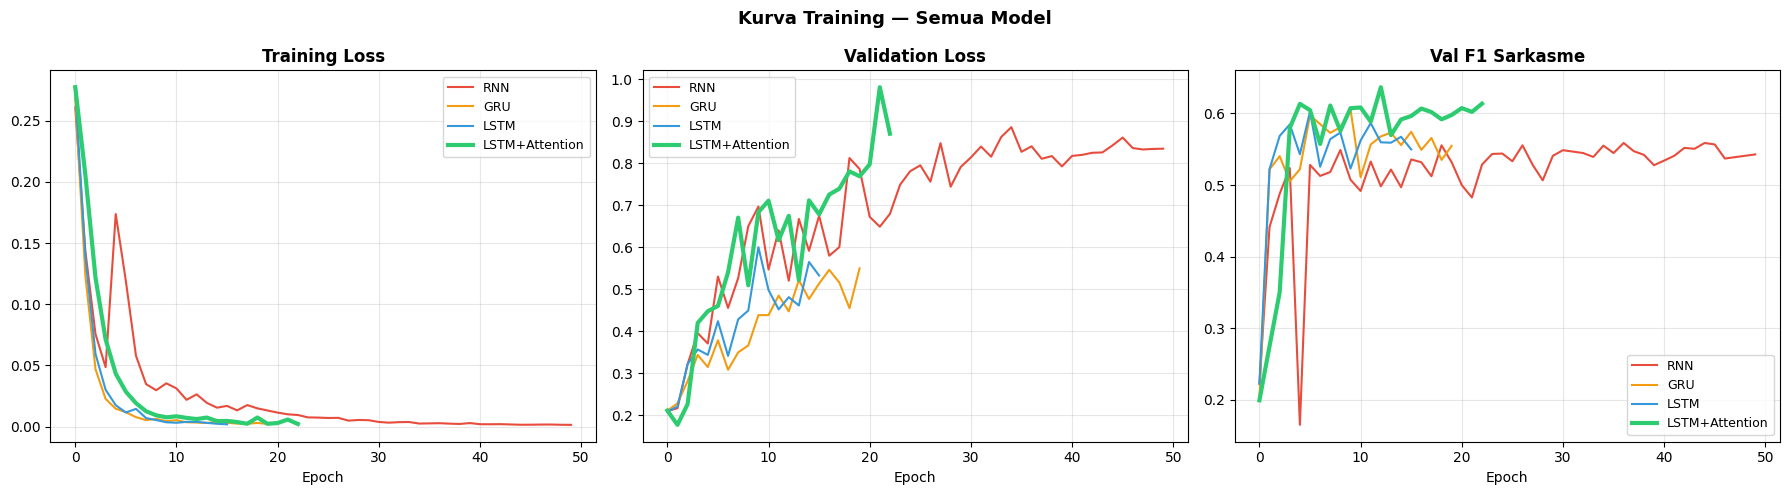

In [40]:
names = list(results.keys())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Kurva Training — Semua Model', fontsize=13, fontweight='bold')

for n, h in all_histories.items():
    lw = 3 if n == 'LSTM+Attention' else 1.5
    axes[0].plot(h['train_loss'],  label=n, color=MC[n], lw=lw)
    axes[1].plot(h['val_loss'],    label=n, color=MC[n], lw=lw)
    axes[2].plot(h['val_f1_sarc'], label=n, color=MC[n], lw=lw)

for ax, t in zip(axes, ['Training Loss','Validation Loss','Val F1 Sarkasme']):
    ax.set_title(t, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('kurva_training.png', dpi=150, bbox_inches='tight')
plt.show()

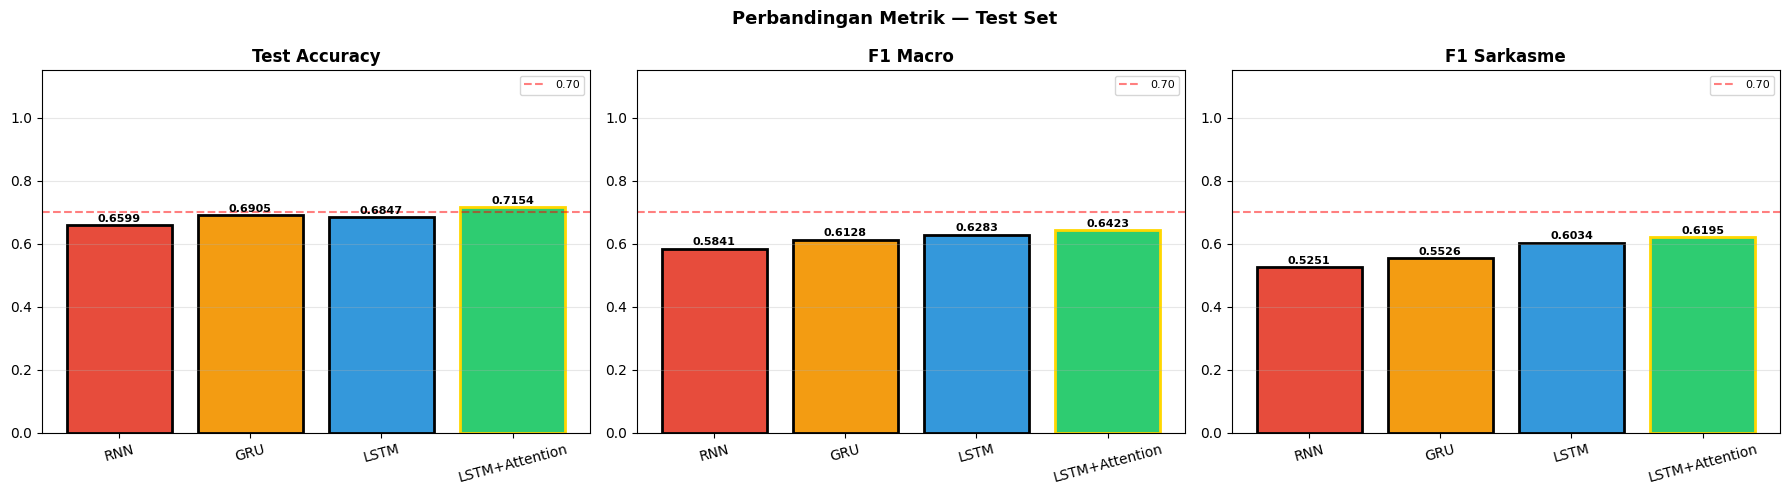

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Perbandingan Metrik — Test Set', fontsize=13, fontweight='bold')

for ax, (metric, title) in zip(axes, [
    ('accuracy',  'Test Accuracy'),
    ('f1_macro',  'F1 Macro'),
    ('f1_sarcasm','F1 Sarkasme'),
]):
    vals = [results[n][metric] for n in names]
    edge = ['gold' if n=='LSTM+Attention' else 'black' for n in names]
    bars = ax.bar(names, vals, color=[MC[n] for n in names],
                  edgecolor=edge, linewidth=2)
    ax.set_title(title, fontweight='bold')
    ax.set_ylim(0, 1.15)
    ax.axhline(0.7, color='red', linestyle='--', alpha=0.5, label='0.70')
    ax.grid(alpha=0.3, axis='y')
    ax.tick_params(axis='x', rotation=15)
    ax.legend(fontsize=8)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                f'{v:.4f}', ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('perbandingan_metrik.png', dpi=150, bbox_inches='tight')
plt.show()

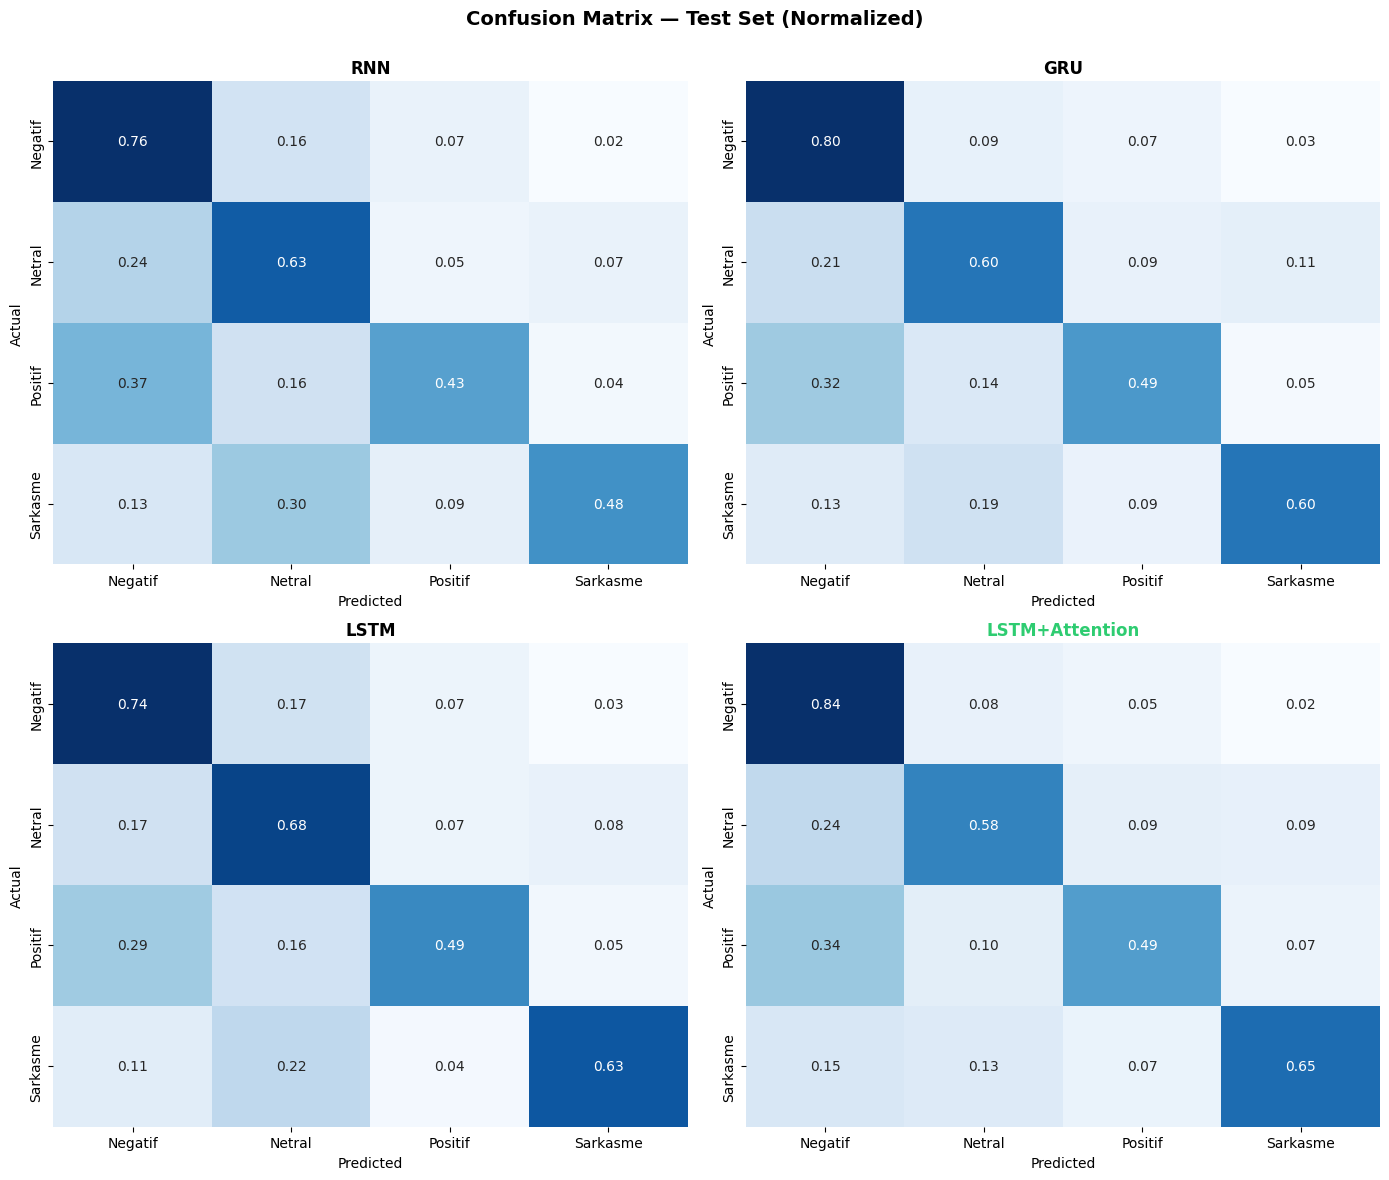

In [42]:
# Ubah menjadi 2 baris, 2 kolom dan sesuaikan ukuran kanvas (misal 14x12)
fig, axes = plt.subplots(2, 2, figsize=(14, 12)) 
fig.suptitle('Confusion Matrix \u2014 Test Set (Normalized)', fontsize=14, fontweight='bold')

# Tambahkan .flatten() pada axes agar array 2D berubah menjadi 1D untuk iterasi
for ax, name in zip(axes.flatten(), names):
    cm_norm = confusion_matrix(
        results[name]['y_true'], results[name]['y_pred'], normalize='true')
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                cbar=False, annot_kws={'size' :10})
    color = '#2ecc71' if name == 'LSTM+Attention' else 'black'
    ax.set_title(name, fontweight='bold', color=color)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
# Memberikan ruang ekstra di bagian atas agar suptitle tidak tertimpa
fig.subplots_adjust(top=0.92) 

plt.savefig('confusion_matrix_2x2.png', dpi=150, bbox_inches='tight')
plt.show()

ABSA — Hasil Prediksi LSTM+Attention (Test Set, Aspect-Conditioned)

Aspek          negatif    netral   positif  sarkasme     TOTAL
--------------------------------------------------------------
kiper               18        11         5         5        39
pelatih            220        70        29        23       342
pemain             166        50        35        27       278
tim                265        95        58        37       455
umum               177       102        54        60       393
wasit               33        15         8         4        60


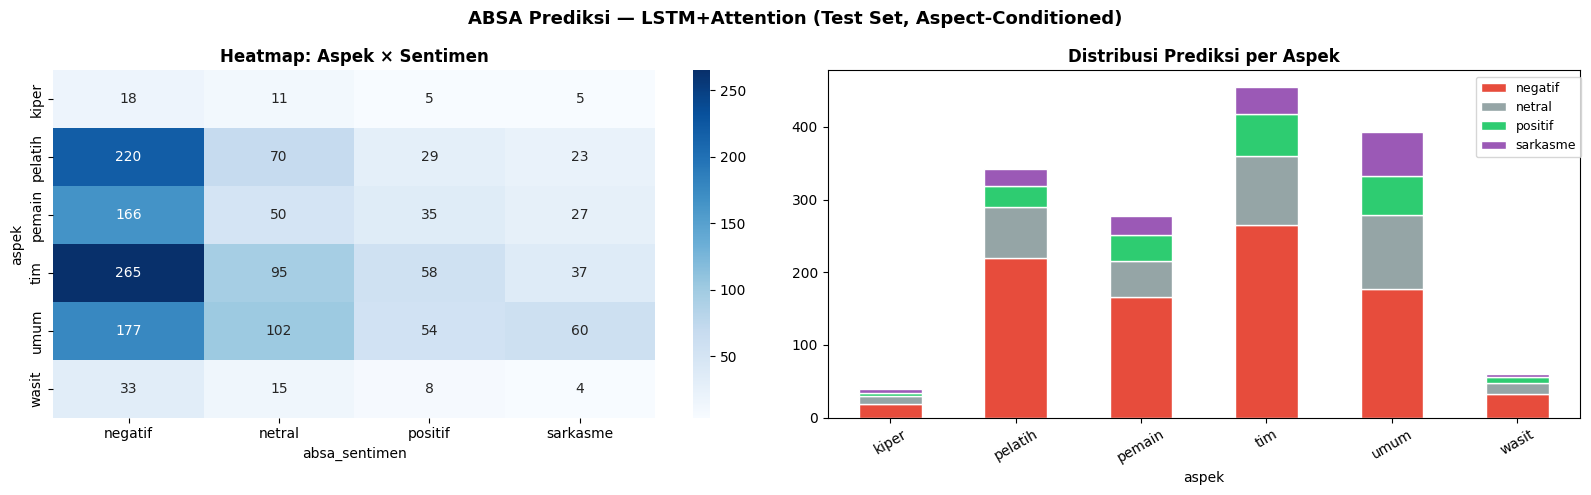


CONTOH OUTPUT ABSA: Aspek dikondisikan di input model
Teks                                     Aspek      Sentimen     P(Sarc)   P(Not)
------------------------------------------------------------------------------------------
watafuck is liverpool doing! just change tim        negatif       0.0029   0.9971
it´s time to go, arne. the team obviousl tim        netral        0.0019   0.9981
i honestly can t take it anymore after l pemain     negatif       0.0032   0.9968
female commentator voice in football is  umum       negatif       0.0023   0.9977
can’t even show the second wolves goal b umum       sarkasme      0.9596   0.0404
salah and gabko gonna sack slot for sure pelatih    negatif       0.0036   0.9964
i think it’s not only arne slot and rich pelatih    positif       0.0036   0.9964
get rid of alisson he is not like before kiper      negatif       0.0034   0.9966
lini depan nya egois semua               umum       netral        0.0019   0.9981
liverpool should have retained the

In [43]:
# ── ABSA Final: hasil prediksi test set (aspect-conditioned) ──────────────
attn_model = trained_models['LSTM+Attention']
attn_model.eval()

all_probs, all_labels_test = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        probs = torch.softmax(attn_model(xb.to(DEVICE)), dim=1).cpu().numpy()
        all_probs.extend(probs)
        all_labels_test.extend(yb.numpy())

all_probs       = np.array(all_probs)
all_labels_test = np.array(all_labels_test)
all_preds_test  = apply_threshold(all_probs, best_thresh['LSTM+Attention'])

# ── Rekonstruksi teks + ekstrak aspek dari token pertama ─────────────────
idx2word = {v: k for k, v in word2idx.items()}

test_texts   = []
test_aspects = []
for seq in Xte_seq:
    # Token pertama = aspect token (mis. <ASP_PEMAIN>)
    asp_word = idx2word.get(int(seq[0]), '<ASP_UMUM>')
    asp_name = asp_word.replace('<ASP_', '').replace('>', '').lower()
    test_aspects.append(asp_name if asp_name in ASPECT_NAMES else 'umum')
    # Rekonstruksi teks (skip token pertama = aspect token)
    teks = ' '.join([idx2word.get(int(t), '') for t in seq[1:] if int(t) > 1])
    test_texts.append(teks)

# ── Buat ABSA records dari prediksi ──────────────────────────────────────
SENT_IDX2STR = {0: 'negatif', 1: 'netral', 2: 'positif', 3: 'sarkasme'}

absa_pred_records = []
for i, (teks, asp, pred) in enumerate(zip(test_texts, test_aspects, all_preds_test)):
    sent = SENT_IDX2STR[pred]
    absa_pred_records.append({
        'teks':          teks[:80],
        'aspek':         asp,
        'label_pred':    LABEL_NAMES[pred],
        'label_true':    LABEL_NAMES[all_labels_test[i]],
        'absa_sentimen': sent,
        'prob_negatif':  round(all_probs[i][0], 4),
        'prob_netral':   round(all_probs[i][1], 4),
        'prob_positif':  round(all_probs[i][2], 4),
        'prob_sarkasme': round(all_probs[i][3], 4),
    })

df_absa_pred = pd.DataFrame(absa_pred_records)
df_absa_pred.to_csv('absa_prediksi_test.csv', index=False)

# ── Tabel pivot ───────────────────────────────────────────────────────────
print('='*70)
print('ABSA — Hasil Prediksi LSTM+Attention (Test Set, Aspect-Conditioned)')
print('='*70)

absa_pred_pivot = df_absa_pred.groupby(['aspek','absa_sentimen']).size().unstack(fill_value=0)
for col in ['negatif','netral','positif','sarkasme']:
    if col not in absa_pred_pivot.columns:
        absa_pred_pivot[col] = 0
absa_pred_pivot = absa_pred_pivot[['negatif','netral','positif','sarkasme']]
absa_pred_pivot['TOTAL'] = absa_pred_pivot.sum(axis=1)

print(f"\n{'Aspek':<12}", end='')
for col in absa_pred_pivot.columns:
    print(f'{col:>10}', end='')
print()
print('-'*62)
for asp in absa_pred_pivot.index:
    print(f'{asp:<12}', end='')
    for col in absa_pred_pivot.columns:
        print(f'{absa_pred_pivot.loc[asp,col]:>10}', end='')
    print()
print('='*62)

# ── Visualisasi ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('ABSA Prediksi — LSTM+Attention (Test Set, Aspect-Conditioned)',
             fontsize=13, fontweight='bold')

pivot_plot2 = absa_pred_pivot.drop(columns='TOTAL')
sns.heatmap(pivot_plot2, annot=True, fmt='d', cmap='Blues',
            ax=axes[0], annot_kws={'size':10})
axes[0].set_title('Heatmap: Aspek × Sentimen', fontweight='bold')

pivot_plot2.plot(kind='bar', stacked=True, ax=axes[1],
                 color=[SENT_COLORS[c] for c in pivot_plot2.columns],
                 edgecolor='white')
axes[1].set_title('Distribusi Prediksi per Aspek', fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(bbox_to_anchor=(1.01,1), fontsize=9)

plt.tight_layout()
plt.savefig('absa_prediksi.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Contoh output ─────────────────────────────────────────────────────────
print('\n' + '='*90)
print('CONTOH OUTPUT ABSA: Aspek dikondisikan di input model')
print('='*90)
print(f'{"Teks":<40} {"Aspek":<10} {"Sentimen":<10} {"P(Sarc)":>9} {"P(Not)":>8}')
print('-'*90)
shown = set()
for _, row in df_absa_pred.iterrows():
    key = (row['aspek'], row['absa_sentimen'])
    if key not in shown:
        shown.add(key)
        p_sarc = row['prob_sarkasme']
        print(f"{row['teks'][:40]:<40} {row['aspek']:<10} "
              f"{row['absa_sentimen']:<10} {p_sarc:>9.4f} {1-p_sarc:>8.4f}")
    if len(shown) >= 20:
        break
print('\n(Tabel lengkap tersimpan di absa_prediksi_test.csv)')

In [44]:
LABEL_DECODE = {0:'Negatif 😠', 1:'Netral 😐', 2:'Positif 😊', 3:'Sarkasme 🤡'}

def predict_with_absa(text):
    cleaned = preprocess(text)

    # ── Deteksi aspek dari teks ──────────────────────────────────────────
    detected_aspects = []
    tl = cleaned.lower()
    for asp, keywords in ASPECT_KEYWORDS.items():
        if any(kw in tl for kw in keywords):
            detected_aspects.append(asp)
    if not detected_aspects:
        detected_aspects = ['umum']

    print('='*72)
    print(f'Komentar        : "{text}"')
    print(f'Aspek terdeteksi: {detected_aspects}')
    print('-'*72)

    m = trained_models['LSTM+Attention']
    m.eval()

    # ── Prediksi sentimen per aspek (model dikondisikan pada aspek) ──────
    print(f'\n{"Aspek":<12} {"Sentimen (LSTM+Att)":<20} '
          f'{"P(Neg)":>8} {"P(Net)":>8} {"P(Pos)":>8} {"P(Sarc)":>8}')
    print('-'*72)
    for asp in detected_aspects:
        x = torch.LongTensor([text_to_seq(cleaned, asp)]).to(DEVICE)
        with torch.no_grad():
            probs = torch.softmax(m(x), dim=1)[0].cpu().numpy()
        pred = int(np.where(probs[3] >= best_thresh['LSTM+Attention'], 3, probs.argmax()))
        print(f'{asp:<12} {LABEL_DECODE[pred]:<20} '
              f'{probs[0]:>8.4f} {probs[1]:>8.4f} {probs[2]:>8.4f} {probs[3]:>8.4f}')

    # ── Perbandingan semua model (aspek pertama) ─────────────────────────
    first_asp = detected_aspects[0]
    x_first   = torch.LongTensor([text_to_seq(cleaned, first_asp)]).to(DEVICE)
    print(f'\nPerbandingan semua model (aspek: {first_asp}):')
    for name, model in trained_models.items():
        model.eval()
        with torch.no_grad():
            probs  = torch.softmax(model(x_first), dim=1)[0].cpu().numpy()
        pred   = int(np.where(probs[3] >= best_thresh[name], 3, probs.argmax()))
        marker = ' ←' if name == 'LSTM+Attention' else ''
        print(f'  [{name:<16}] → {LABEL_DECODE[pred]:<18} (conf:{probs[pred]:.4f}){marker}')

    # ── Attention weights ────────────────────────────────────────────────
    tokens = [ASPECT2TOKEN[first_asp]] + cleaned.lower().split()[:MAX_SEQ_LEN-1]
    if hasattr(m, 'get_attention_weights') and len(tokens) > 0:
        with torch.no_grad():
            wts = m.get_attention_weights(x_first)[0].cpu().numpy()[:len(tokens)]
        top = sorted(zip(tokens, wts), key=lambda z: z[1], reverse=True)[:5]
        print(f'\nAttention Top-5 (aspek: {first_asp}):')
        for word, w in top:
            bar = '█' * int(w * 40)
            print(f'  {word:<20}: {bar:<40} {w:.4f}')
    print()


# ── Test ────────────────────────────────────────────────────────────────────
for komentar in [
    "wow great job losing at home again, truly world class team",
    "Salah scored a wonder goal but the defence was absolutely terrible",
    "Slot tactics are genius but Van Dijk had a nightmare game",
    "brilliant defending, only conceded 4 in the first half",
    "what an amazing goal from Salah, so proud of this team",
    "The match ended 1-1 tonight at Anfield",
    "hebat banget kalah terus emang juara memang",
    "goalkeeper skill is great 😂😂",
    "truly inspiring, same formation same result, genius coaching",
    "Slot has no idea but Salah is still world class",
]:
    predict_with_absa(komentar)

Komentar        : "wow great job losing at home again, truly world class team"
Aspek terdeteksi: ['tim']
------------------------------------------------------------------------

Aspek        Sentimen (LSTM+Att)    P(Neg)   P(Net)   P(Pos)  P(Sarc)
------------------------------------------------------------------------
tim          Sarkasme 🤡             0.0063   0.0016   0.0126   0.9795

Perbandingan semua model (aspek: tim):
  [RNN             ] → Sarkasme 🤡         (conf:0.9935)
  [GRU             ] → Sarkasme 🤡         (conf:0.9815)
  [LSTM            ] → Sarkasme 🤡         (conf:0.9816)
  [LSTM+Attention  ] → Sarkasme 🤡         (conf:0.9795) ←

Attention Top-5 (aspek: tim):
  truly               : █████████████                            0.3447
  again,              : ███████                                  0.1988
  world               : ████                                     0.1110
  class               : ███                                      0.0754
  great               :

In [45]:
# Cek: pakai threshold 0.5 (argmax biasa) untuk LSTM+Attention
attn_model = trained_models['LSTM+Attention']
yt, probs  = get_probs(attn_model, test_loader)

print(f"{'Threshold':>10} {'Accuracy':>10} {'F1-Macro':>9} {'F1-Sarc':>9} {'TP-Sarc':>8} {'FP-Sarc':>8}")
print('-' * 58)

for thresh in [0.35, 0.37, 0.40, 0.42, 0.44, 0.46, 0.48, 0.50]:
    preds = apply_threshold(probs, thresh)
    acc   = accuracy_score(yt, preds)
    f1m   = f1_score(yt, preds, average='macro', zero_division=0)
    f1s_  = f1_score(yt, preds, labels=[3], average=None, zero_division=0)
    f1s   = f1s_[0] if len(f1s_) > 0 else 0.0
    tp    = sum(1 for i,p in enumerate(preds) if p==3 and yt[i]==3)
    fp    = sum(1 for i,p in enumerate(preds) if p==3 and yt[i]!=3)
    print(f"{thresh:>10.2f} {acc:>10.4f} {f1m:>9.4f} {f1s:>9.4f} {tp:>8} {fp:>8}")

 Threshold   Accuracy  F1-Macro   F1-Sarc  TP-Sarc  FP-Sarc
----------------------------------------------------------
      0.35     0.7154    0.6423    0.6195       92       64
      0.37     0.7147    0.6413    0.6169       91       63
      0.40     0.7179    0.6459    0.6276       91       58
      0.42     0.7179    0.6453    0.6250       90       57
      0.44     0.7179    0.6453    0.6250       90       57
      0.46     0.7173    0.6444    0.6224       89       56
      0.48     0.7173    0.6444    0.6224       89       56
      0.50     0.7173    0.6452    0.6268       89       54
